# Header

In [1]:
from utils import *

In [2]:
import sys
sys.path.insert(0, '/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src')
import cna

In [3]:
import gseapy as gp
import scanpy as sc
from itertools import product
from matplotlib.patches import Patch

In [4]:
os.chdir('../')

In [5]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [6]:
with open('data/Legends/celltypelevel3_palette.pkl','rb') as f:
    palette_all = pkl.load(f)

palette_all

{'Naive B': (0.843137, 0.0, 0.0),
 'Mature B': (0.54902, 0.235294, 1.0),
 'Memory B': (0.007843, 0.533333, 0.0),
 'Plasmablast': (0.0, 0.67451, 0.780392),
 'Naive CD4T': (0.596078, 1.0, 0.0),
 'Central Memory CD4T': (1.0, 0.498039, 0.819608),
 'Effector Memory CD4T': (0.423529, 0.0, 0.309804),
 'Cytotoxic CD4T': (1.0, 0.647059, 0.188235),
 'Treg': (0.345098, 0.231373, 0.0),
 'Naive CD8T': (0.0, 0.341176, 0.34902),
 'Central Memory CD8T': (0.0, 0.0, 0.866667),
 'Effector Memory CD8T': (0.0, 0.992157, 0.811765),
 'Double Negative T': (0.631373, 0.458824, 0.415686),
 'γδ T': (0.737255, 0.717647, 1.0),
 'MAIT': (0.584314, 0.709804, 0.470588),
 'cDC1': (0.752941, 0.015686, 0.72549),
 'cDC2': (0.392157, 0.329412, 0.454902),
 'pDC': (0.47451, 0.0, 0.0),
 'Classical Monocyte': (0.027451, 0.454902, 0.847059),
 'Intermediate Monocyte': (0.996078, 0.960784, 0.564706),
 'Nonclassical Monocyte': (0.0, 0.294118, 0.0),
 'Cytotoxic Monocyte': (0.560784, 0.478431, 0.0),
 'CD56-dim NK': (1.0, 0.447059, 

In [7]:
with open('data/Legends/metadata_palette.pkl','rb') as f:
    palette_metadata = pkl.load(f)

palette_metadata


FileNotFoundError: [Errno 2] No such file or directory: 'data/Legends/metadata_palette.pkl'

In [12]:
major_celltype_palette = {
    'B':    '#3072C4',   # strong blue
    'T':    '#EF763F',   # bold orange
    'DC':   '#35A293',   # teal
    'Mono': '#B3813E',   # rich brown/gold
    'NK':   '#7D4C99',   # deep purple
}

cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}

# Load data

In [8]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', index_col=0)
#meta.index = [x.replace('_','-') for x in meta.index]

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL', 'NHW-DCIS', 'NHW-BC','NHB-HRL', 'NHB-DCIS', 'NHB-BC'],
    ordered=True
    )

meta

,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
sampleid,,,,,,,,,
9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS
30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,N,NHB-DCIS
119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,N,NHB-DCIS
28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [9]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)

dat

/n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new/lib/python3.12/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData object with n_obs × n_vars = 434565 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3', 'sampleid', 'batch', 'viability_pct', 'group', 'race', 'age', 'diabetes', 'obesity', 'race_stage'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_co

In [14]:
# for col in ['sampleid', 'age', 'race-stage', 'race', 'group', 'diabetes', 'obesity']:
#     dat.obs[col] = dat.obs['dataset_name'].map(meta.set_index('dataset_name')[col])
    
for xcol in ['diabetes','obesity']:
    dat.obs[xcol] = [1 if x=='Y' else 0 for x in dat.obs[xcol]]

xcol = 'group'
dat.obs[xcol] = [0 if x=='HRL' else 1 if x=='DCIS' else 2 for x in dat.obs[xcol]]

xcol = 'race'
dat.obs[xcol] = [0 if x=='NHW' else 1 if x=='NHB' else None for x in dat.obs[xcol]]

dat.obs.columns

Index(['nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts',
       'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA',
       'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score',
       'predicted.celltype.l1', 'predicted.celltype.l2.score',
       'predicted.celltype.l2', 'predicted.celltype.l3.score',
       'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8',
       'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score',
       'G2M.Score', 'Phase', 'celltype_level3', 'sampleid', 'batch',
       'viability_pct', 'group', 'race', 'age', 'diabetes', 'obesity',
       'race_stage'],
      dtype='object')

# DC, CNA


In [15]:
celltype_major = 'DC'

In [17]:
d = pkl.load(
    open('data/Figure6/DC_NAM_GeneModuleScored_immport.pkl','rb')
)
d

AnnData object with n_obs × n_vars = 8012 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3', 'sampleid', 'age', 'race-stage', 'race', 'group', 'diabetes', 'obesity', 'race_coef', 'race_coef_fdr', 'INTERLEUKIN-12 FAMILY SIGNALING', 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR SIGNALING PATHWAY', 'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS', 'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY', 'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS', 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE', 'INTERL

In [14]:
d = dat[dat.obs['predicted.celltype.l1']==celltype_major]

In [15]:
# d = dat[dat.obs['predicted.celltype.l1']==celltype_major]

sc.pp.neighbors(d)

In [16]:
umap = pd.read_csv(f"data/03_cleandata/ft_{celltype_major}_UmapCoords.csv",
                   index_col=0
                  ).loc[d.obs.index,:]

d.obsm['X_umap'] = umap.values

In [14]:
samplem = cna.ut.obs_to_sample(d,                           # the dataset
                               ['group','race','age','obesity','diabetes'],     # the metadata columns to use
                               'dataset_name')                        # the column of d.obs that contains sample IDs

samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]

print(Counter(samplem.group))
samplem

Counter({2.0: 26, 0.0: 20, 1.0: 10})


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)


,group,race,age,obesity,diabetes,batch
Pool137_10,0.0,0.0,62.3,0.0,0.0,Pool137
Pool137_11,2.0,0.0,48.0,0.0,0.0,Pool137
Pool137_12,1.0,0.0,78.0,0.0,0.0,Pool137
Pool137_14,0.0,0.0,42.5,1.0,0.0,Pool137
Pool137_15,2.0,0.0,67.0,0.0,0.0,Pool137
Pool137_16,2.0,1.0,60.0,1.0,0.0,Pool137
Pool137_17,2.0,1.0,54.0,1.0,0.0,Pool137
Pool137_18,1.0,1.0,39.0,0.0,0.0,Pool137
Pool137_19,2.0,0.0,79.0,0.0,0.0,Pool137
Pool137_20,1.0,1.0,80.0,0.0,0.0,Pool137


In [18]:
res = cna.tl.association(
    d,
    samplem.race, 
    'dataset_name',
    covs=samplem[['age', 'group','obesity','diabetes']],
    batches=samplem.batch,
    key_added='race_coef',
    return_full=True
)

/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\


In [16]:
pkl.dump(res, 
         open('data/Figure6/fullres_DC.pkl', 'wb'))

In [10]:
res = pkl.load(
    open('data/Figure6/fullres_DC.pkl', 'rb')
)

In [11]:
U, svs, V = cna.tl.svd_nam(res.nam)
svs/svs.sum()

PC1     1.827121e-01
PC2     1.043149e-01
PC3     8.678969e-02
PC4     6.177716e-02
PC5     5.251752e-02
PC6     3.814771e-02
PC7     3.464752e-02
PC8     3.077295e-02
PC9     2.936434e-02
PC10    2.586577e-02
PC11    2.415697e-02
PC12    2.236191e-02
PC13    1.953382e-02
PC14    1.773923e-02
PC15    1.588862e-02
PC16    1.522635e-02
PC17    1.346388e-02
PC18    1.316370e-02
PC19    1.145560e-02
PC20    1.106186e-02
PC21    1.025903e-02
PC22    9.987737e-03
PC23    9.636382e-03
PC24    9.482655e-03
PC25    8.876341e-03
PC26    8.424423e-03
PC27    7.897227e-03
PC28    7.648176e-03
PC29    7.556827e-03
PC30    7.168840e-03
PC31    6.680848e-03
PC32    6.559263e-03
PC33    6.017592e-03
PC34    5.903546e-03
PC35    5.732994e-03
PC36    5.241086e-03
PC37    5.154670e-03
PC38    5.017954e-03
PC39    4.766847e-03
PC40    4.689757e-03
PC41    4.430624e-03
PC42    4.220770e-03
PC43    3.849036e-03
PC44    3.642311e-03
PC45    3.529841e-03
PC46    3.421484e-03
PC47    3.105237e-03
PC48    2.922

In [15]:
U, svs, V = cna.tl.svd_nam(res.nam)


d.obs.loc[res.kept, 'NAMPC1'] = V.PC1
d.obs.loc[res.kept, 'NAMPC2'] = V.PC2
d.obs.loc[res.kept, 'NAMPC3'] = V.PC3
d.obs.loc[res.kept, 'NAMPC4'] = V.PC4

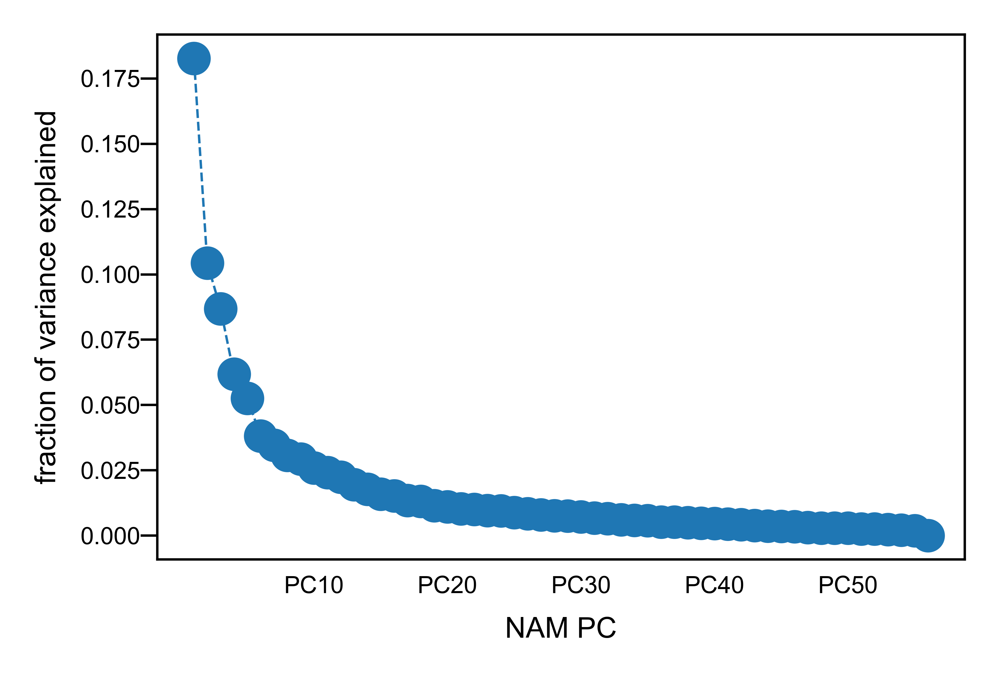

In [18]:
# plot variance explained by each NAM PC
plt.figure(figsize=(3,2))
plt.plot(svs/svs.sum(), marker='o', linestyle='--')
plt.xlabel('NAM PC')
plt.ylabel('fraction of variance explained')
plt.xticks([9, 19, 29, 39, 49])
plt.show()


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, f_oneway, spearmanr

def sample_loading_plot_by_pheno(
    U: pd.DataFrame,
    pheno: pd.Series,
    title: str | None = None,
    figsize=(1.8, 1.4),
    PCs=(1, 2),
    label_dict: dict | None = None,
    color_dict: dict | None = None,
    scatter_kwargs: dict | None = None,
    mode: str = 'auto',                # 'auto' | 'categorical' | 'continuous'
    categorical_if_nunique_le: int = 5 # treat low-cardinality numeric as categorical
):
    """
    - If pheno is categorical: one scatter (x=PC1, y=PC2), colored by groups.
      Also test PC1 and PC2 across groups (MWU if 2 groups; ANOVA if >=3).
    - If pheno is numeric: two scatters (x=pheno, y=PC1/PC2).
      Also Spearman correlation for PC1~pheno and PC2~pheno.

    Returns
    -------
    fig : matplotlib Figure
    results : dict with test statistics/p-values
    """
    if scatter_kwargs is None:
        scatter_kwargs = dict(s=12, alpha=0.85)

    # Align indices
    pheno = pheno.loc[U.index]
    pcx, pcy = f'PC{PCs[0]}', f'PC{PCs[1]}'
    if pcx not in U or pcy not in U:
        raise ValueError(f"U must contain columns '{pcx}' and '{pcy}'")

    # ---- mode inference ----
    def infer_mode(s: pd.Series) -> str:
        if mode in ('categorical', 'continuous'):
            return mode
        if pd.api.types.is_object_dtype(s) or pd.api.types.is_categorical_dtype(s) or pd.api.types.is_bool_dtype(s):
            return 'categorical'
        if pd.api.types.is_numeric_dtype(s):
            nunique = s.dropna().nunique()
            return 'categorical' if nunique <= categorical_if_nunique_le else 'continuous'
        return 'categorical'

    actual_mode = infer_mode(pheno)
    results = {'mode': actual_mode, 'PC1': None, 'PC2': None}

    # ==========================
    # CATEGORICAL phenotype
    # ==========================
    if actual_mode == 'categorical':
        # preserve order of first appearance
        vals = pheno.dropna()
        levels = []
        for v in vals:
            if v not in levels:
                levels.append(v)

        def disp(x):
            return label_dict.get(x, x) if label_dict else str(x)

        fig, ax = plt.subplots(figsize=figsize)
        for raw_lab in levels:
            idx = (pheno == raw_lab)
            label = disp(raw_lab)
            color = color_dict.get(label, None) if color_dict else None
            ax.scatter(U.loc[idx, pcx], U.loc[idx, pcy],
                       label=label, c=color, **scatter_kwargs)

        ax.set_xlabel(f'NAM {pcx}', fontsize=7)
        ax.set_ylabel(f'NAM {pcy}', fontsize=7)
        if title:
            ax.set_title(title, fontsize=8)
        ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5),
                  fontsize=6, frameon=False)
        fig.tight_layout()

        # --- stats on PC1 and PC2 separately ---
        groups_x = [U.loc[pheno == g, pcx].dropna() for g in levels]
        groups_y = [U.loc[pheno == g, pcy].dropna() for g in levels]

        print(f"\n[Categorical phenotype] Groups: {levels}")
        if len(levels) == 2:
            ux = mannwhitneyu(groups_x[0], groups_x[1], alternative='two-sided')
            uy = mannwhitneyu(groups_y[0], groups_y[1], alternative='two-sided')
            print(f"Mann–Whitney U (PC{PCs[0]}): U={ux.statistic:.3g}, p={ux.pvalue:.3g}")
            print(f"Mann–Whitney U (PC{PCs[1]}): U={uy.statistic:.3g}, p={uy.pvalue:.3g}")
            results['PC1'] = {'test':'Mann-Whitney U', 'stat': float(ux.statistic), 'p': float(ux.pvalue)}
            results['PC2'] = {'test':'Mann-Whitney U', 'stat': float(uy.statistic), 'p': float(uy.pvalue)}
        elif len(levels) >= 3:
            ax1 = f_oneway(*groups_x)
            ax2 = f_oneway(*groups_y)
            print(f"One-way ANOVA (PC{PCs[0]}): F={ax1.statistic:.3g}, p={ax1.pvalue:.3g}")
            print(f"One-way ANOVA (PC{PCs[1]}): F={ax2.statistic:.3g}, p={ax2.pvalue:.3g}")
            results['PC1'] = {'test':'ANOVA', 'stat': float(ax1.statistic), 'p': float(ax1.pvalue)}
            results['PC2'] = {'test':'ANOVA', 'stat': float(ax2.statistic), 'p': float(ax2.pvalue)}
        else:
            print("Not enough groups for hypothesis testing.")

        return fig, results

    # ==========================
    # CONTINUOUS phenotype
    # ==========================
    x = pd.to_numeric(pheno, errors='coerce').astype(float)
    fig, axes = plt.subplots(
        1, 2,
        figsize=(max(figsize[0]*2.2, 3.2), figsize[1]),
        sharex=False, sharey=False
    )
    for ax, pc, key in zip(axes, (pcx, pcy), ('PC1', 'PC2')):
        y = pd.to_numeric(U[pc], errors='coerce').astype(float)
        m = np.isfinite(x) & np.isfinite(y)
        ax.scatter(x[m], y[m], **scatter_kwargs)
        ax.set_xlabel(pheno.name if pheno.name else 'Phenotype', fontsize=7)
        ax.set_ylabel(f'NAM {pc}', fontsize=7)

        if m.sum() > 1:
            rho, p = spearmanr(x[m], y[m])
            print(f"Spearman (NAM {pc} ~ {pheno.name or 'phenotype'}): ρ={rho:.3g}, p={p:.3g}")
            results[key] = {'test':'Spearman', 'rho': float(rho), 'p': float(p)}
        else:
            print(f"Not enough valid points for Spearman on NAM {pc}.")
            results[key] = {'test':'Spearman', 'rho': np.nan, 'p': np.nan}

    if title:
        fig.suptitle(title, fontsize=8, y=1.02)
    fig.tight_layout()
    return fig, results

/tmp/ipykernel_481679/3576625714.py:42: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_object_dtype(s) or pd.api.types.is_categorical_dtype(s) or pd.api.types.is_bool_dtype(s):



[Categorical phenotype] Groups: [0.0, 1.0]
Mann–Whitney U (PC2): U=315, p=0.213
Mann–Whitney U (PC3): U=165, p=0.000211


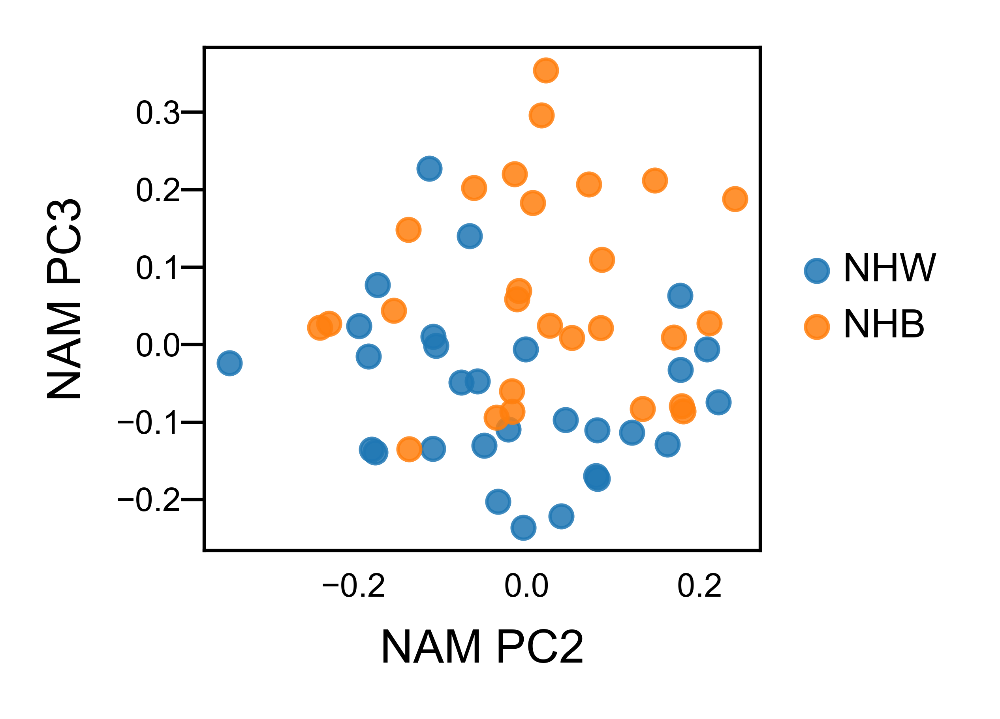

In [16]:
label_dict = {0: 'NHW', 1: 'NHB'}

sample_loading_plot_by_pheno(U,
                             samplem.race, 
                             title='',
                             label_dict=label_dict,
                             PCs = [2,3],
                             figsize=(2.1, 1.5)
                                        )

plt.savefig('plots/Figure6/DC NAM PCs_byRace.svg')

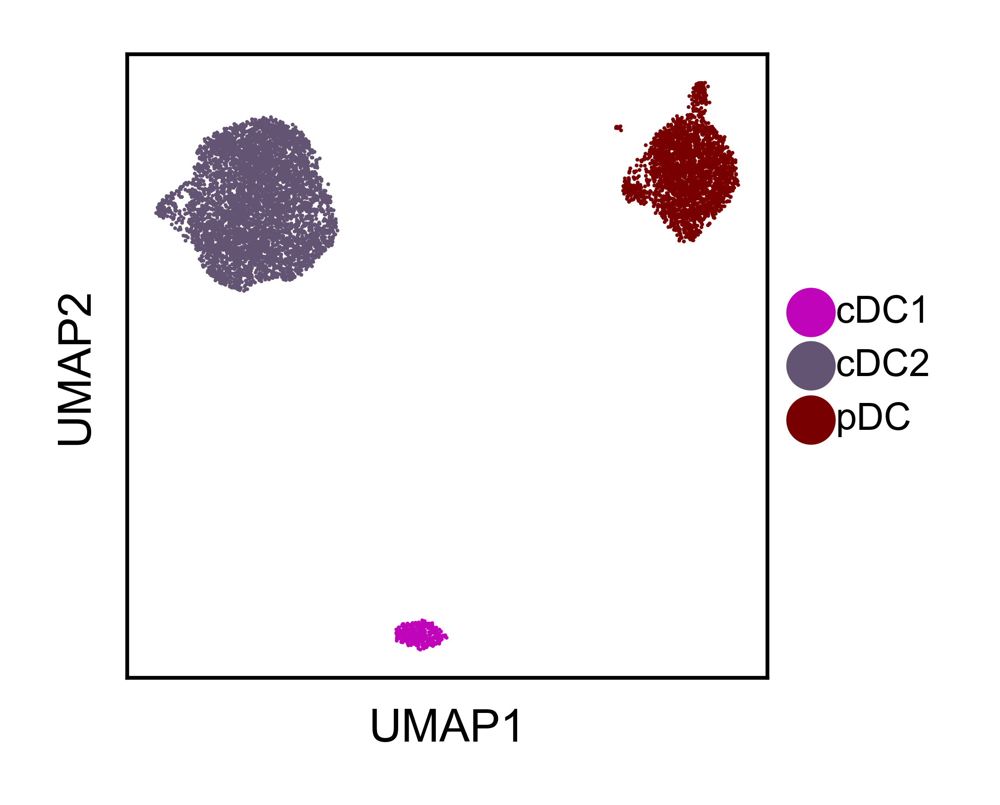

In [18]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'celltype_level3'


order = cells_group['DC']
pal_ordered = [palette_all[c] for c in order]


sc.pl.umap(
    d,
    color='celltype_level3',
    palette=pal_ordered,
    size=1,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig('plots/F6_2/DC_celltype.svg')

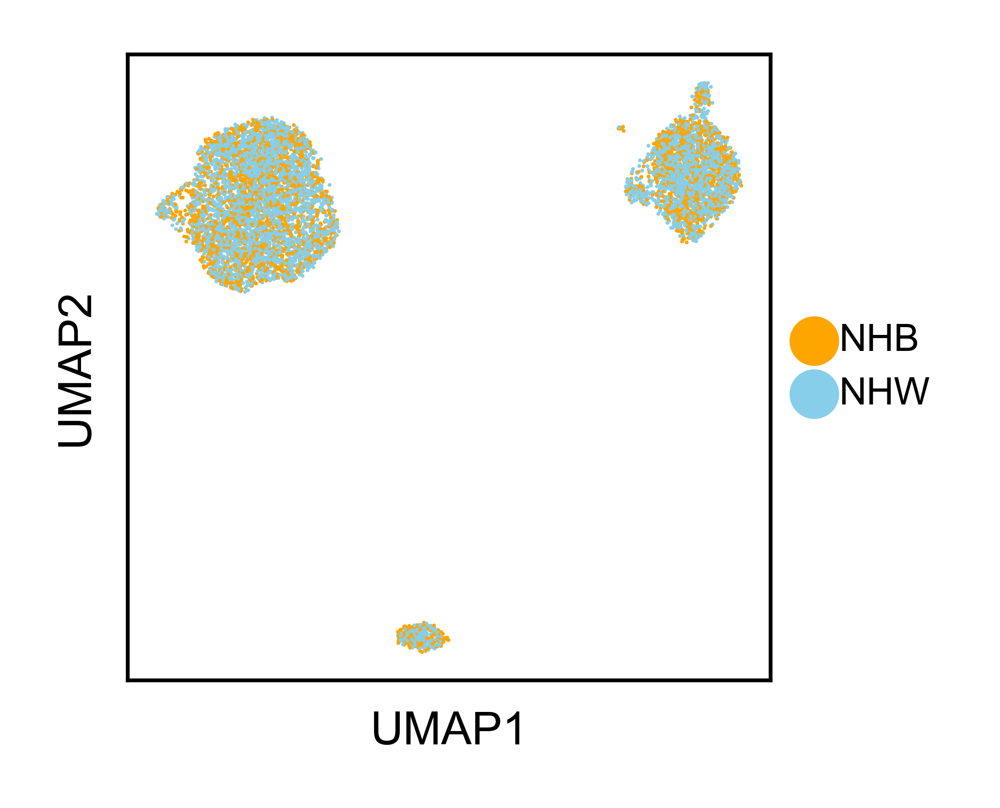

In [25]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'race'
d.obs['race'] = [str(x).replace('1','NHB').replace('0','NHW') for x in d.obs['race']]


order = cells_group['DC']
pal_ordered = [palette_all[c] for c in order]

sc.pl.umap(
    d,
    color=covar,
    palette=['orange','skyblue'],
    size=1,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig('plots/F6_2/DC_race.svg')

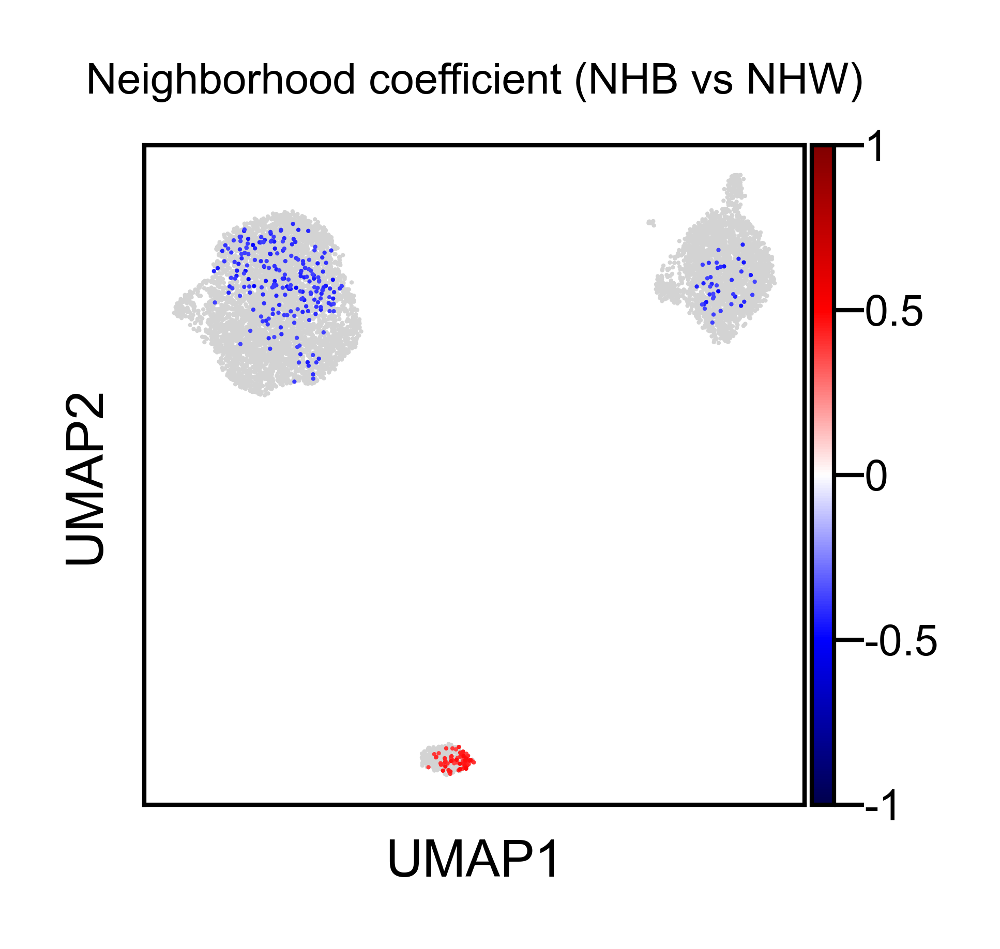

In [24]:
fig, ax = plt.subplots(figsize=(1.5, 1.4))


covar = 'race' 

coef_col = f"{covar}_coef"
fdr_col = f"{covar}_coef_fdr"
color_col = f"{covar}_coef_plot"

d.obs[color_col] = np.where(d.obs[fdr_col] < 0.1, d.obs[coef_col], np.nan)   # nan will show as gray in sc.pl.umap
sc.pl.umap(
    d,
    color=color_col,
    s=1,
    ax=ax,
    vmin=-1,
    vmax=1,
    cmap='seismic',
    na_color='lightgray',   # Gray for nan (non-significant)
    title='',
    show=False         # So you can further edit if needed
)

cbar = ax.collections[0].colorbar
ticks = [-1, -0.5, 0, 0.5, 1]
cbar.set_ticks(ticks)
cbar.set_ticklabels([str(t) for t in ticks])


ax.set_title('Neighborhood coefficient (NHB vs NHW)',fontsize=5)
plt.savefig('plots/F6_2/DC_NbCoeff.svg')

# Num & % of significant cells

In [14]:
d = pkl.load(
    open('data/10_cna/DC.pkl', 'rb')
)

In [15]:
out = d.obs.copy()
out['stage-celltype'] = out['group'].replace(0,'HRL').replace(1,'DCIS').replace(2,'BC').astype(str) + '-' + out['celltype_level3'].astype(str)
Counter(out['stage-celltype'])

covar = 'race'
stages = out['stage-celltype'].unique()


records = []

fdr_col = f'{covar}_coef_fdr'
coef_col = f'{covar}_coef'

for stage in stages:
    subset = out[out['stage-celltype'] == stage]
    sig = subset[subset[fdr_col] < 0.1]
    count_lt_0_1 = len(sig)
    count_ge_0_1 = (subset[fdr_col] >= 0.1).sum()
    # Positive and negative (within significant)
    count_pos = (sig[coef_col] > 0).sum()
    count_neg = (sig[coef_col] < 0).sum()
    pct_pos = (count_pos / (count_lt_0_1 + count_ge_0_1)) * 100 if count_lt_0_1 > 0 else 0
    pct_neg = (count_neg / (count_lt_0_1 + count_ge_0_1)) * 100 if count_lt_0_1 > 0 else 0
    
    records.append({
        'covar': covar,
        'stage-celltype': stage,
        # 'count_fdr_lt_0.1': count_lt_0_1,
        # 'count_fdr_ge_0.1': count_ge_0_1,
        
        # 'pct_sigbyFDR0.1': count_lt_0_1 / (count_lt_0_1 + count_ge_0_1) * 100 if (count_lt_0_1 + count_ge_0_1) > 0 else 0,
        'count_pos_sig': count_pos,
        'count_neg_sig': count_neg,
        'pct_pos_sig': pct_pos,
        'pct_neg_sig': pct_neg
    })

df_counts = pd.DataFrame(records)

df_counts['stage'] = [x.split('-')[0] for x in df_counts['stage-celltype']]
df_counts['celltype'] = [x.split('-')[1] for x in df_counts['stage-celltype']]

df_counts = df_counts[(df_counts['count_pos_sig']>0) | (df_counts['count_neg_sig']>0)]
df_counts

,covar,stage-celltype,count_pos_sig,count_neg_sig,pct_pos_sig,pct_neg_sig,stage,celltype
0,race,HRL-cDC2,0,101,0.000000,4.338488,HRL,cDC2
1,race,HRL-pDC,0,19,0.000000,1.782364,HRL,pDC
2,race,HRL-cDC1,48,0,28.915663,0.000000,HRL,cDC1
3,race,BC-cDC2,0,84,0.000000,3.979157,BC,cDC2
4,race,BC-pDC,0,10,0.000000,0.860585,BC,pDC
5,race,BC-cDC1,13,0,10.156250,0.000000,BC,cDC1
6,race,DCIS-cDC2,0,22,0.000000,3.264095,DCIS,cDC2
7,race,DCIS-cDC1,10,0,20.000000,0.000000,DCIS,cDC1
8,race,DCIS-pDC,0,8,0.000000,2.446483,DCIS,pDC


In [16]:
cells_ordered = [x for x in cells_group['DC'] if x in df_counts['celltype'].values]
print(cells_ordered)


['cDC1', 'cDC2', 'pDC']


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

group_palette = {
    'HRL':  '#1B9E77',  # darker teal-green for positive
    'DCIS': '#D95F02',  # darker orange-rust for positive
    'BC':   '#7570B3',  # darker violet for positive
}

group_palette_dn = {
    'HRL':  '#A6D9C4',  # lighter teal-green for negative
    'DCIS': '#F6B48F',  # lighter orange-peach for negative
    'BC':   '#C1B7E3',  # lighter lavender for negative
}

def plot_posneg_by_stage_celltype(df_counts,
                                  covar_filter=None,
                                  cells_ordered=None,       # list of celltypes in your preferred order
                                  palette_all=None,         # dict: celltype -> color (RGB tuple or hex)
                                  figsize=(5.0, 1.8),
                                  plottype = 'count',
                                  outfile=None):

    df = df_counts.copy()

    # optional filter (e.g., 'race-stage')
    if covar_filter is not None and 'covar' in df.columns:
        df = df[df['covar'] == covar_filter].copy()

    # ensure we have numeric pos/neg (use counts directly here)
    if not {'count_pos_sig','count_neg_sig'}.issubset(df.columns):
        raise ValueError("df_counts must contain 'count_pos_sig' and 'count_neg_sig'.")

    if plottype == 'count':
        df['pos'] = df['count_pos_sig'].astype(float)
        df['neg'] = df['count_neg_sig'].astype(float)

    elif plottype == 'pct':
        df['pos'] = df['pct_pos_sig'].astype(float)
        df['neg'] = df['pct_neg_sig'].astype(float)
        

    # split group from 'stage' which looks like 'HRL-Naive CD4T'
    # group = HRL/DCIS/BC ; celltype is in its own column already
    df['group'] = df['stage'].astype(str)#.str#.split('-', n=1).str[0]

    # ordering: group first, then celltype within group
    group_order = ['HRL', 'DCIS', 'BC']
    df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

    if cells_ordered is None:
        # keep the appearance order of celltypes
        cells_ordered = list(pd.unique(df['celltype']))
    df['celltype'] = pd.Categorical(df['celltype'], categories=cells_ordered, ordered=True)

    df = df.sort_values(['group', 'celltype']).reset_index(drop=True)
    # print(df)

    
    # x positions and labels
    x = range(len(df))
    x_labels = df['celltype'].astype(str).tolist()

    # bar colors
    colors_pos = [group_palette.get(g, '#999999') for g in df['group']]
    # print(colors_pos)
    colors_neg = [group_palette_dn.get(g, '#cccccc') for g in df['group']]

    # plot
    plt.figure(figsize=figsize)
    plt.bar(x, df['pos'].to_numpy(), color=colors_pos, alpha=0.95, width=0.85)
    plt.bar(x, -df['neg'].to_numpy(), color=colors_neg, alpha=0.95, width=0.85)

    ymax = max(df['pos'].max(), df['neg'].max())
    ylim = (-ymax * 1.05, ymax * 1.05)
    plt.axhline(0, color='black', lw=0.7)
    plt.ylim(ylim)
    
    # build symmetric tick positions
    yticks = np.linspace(-ymax, ymax, num=5)  # or use np.arange
    # make all labels positive
    yticklabels = [f"{abs(int(t))}" if t != 0 else "0" for t in yticks]
    
    
    plt.yticks(yticks, yticklabels, fontsize=5)
    
    plt.xlim(-0.5, len(df)-0.5)

    ylabel = 'Number of significant cells' if plottype=='count' else 'Significant cells (%)'
    plt.ylabel(ylabel, fontsize=5)

    # ticks
    plt.xticks(x, x_labels, rotation=30, ha='right', fontsize=5)
    # color tick labels by celltype palette
    if palette_all is not None:
        ax = plt.gca()
        for i, tick in enumerate(ax.get_xticklabels()):
            ct = x_labels[i]
            tick.set_color(palette_all.get(ct, 'black'))

    # vertical separators between HRL | DCIS | BC
    sizes = df.groupby('group', observed=True).size().reindex(group_order).fillna(0).astype(int).tolist()
    boundaries = []
    running = 0
    for sz in sizes[:-1]:
        running += sz
        if sz > 0:
            boundaries.append(running - 0.5)
    for b in boundaries:
        plt.axvline(b, color='gray', ls='--', lw=0.7, alpha=0.8)

    # legend
    legend_handles = [
        plt.Line2D([0], [0], marker='o', color='w', label='HRL, Positive',
                   markerfacecolor=group_palette['HRL'], markersize=6),
        plt.Line2D([0], [0], marker='o', color='w', label='HRL, Negative',
                   markerfacecolor=group_palette_dn['HRL'], markersize=6),
        plt.Line2D([0], [0], marker='o', color='w', label='DCIS, Positive',
                   markerfacecolor=group_palette['DCIS'], markersize=6),
        plt.Line2D([0], [0], marker='o', color='w', label='DCIS, Negative',
                   markerfacecolor=group_palette_dn['DCIS'], markersize=6),
        plt.Line2D([0], [0], marker='o', color='w', label='BC, Positive',
                   markerfacecolor=group_palette['BC'], markersize=6),
        plt.Line2D([0], [0], marker='o', color='w', label='BC, Negative',
                   markerfacecolor=group_palette_dn['BC'], markersize=6),
    ]
    
    plt.legend(handles=legend_handles,
               frameon=False, fontsize=5, ncol=3,
               loc='upper center', bbox_to_anchor=(0.5, 1.3),
               handlelength=0.8, handleheight=0.8, borderpad=0.2)

    # ax.set_yscale('symlog', linthresh=1) 

    
    plt.tight_layout()
    if outfile:
        plt.savefig(outfile, bbox_inches='tight', transparent=True, dpi=300)
    plt.show()

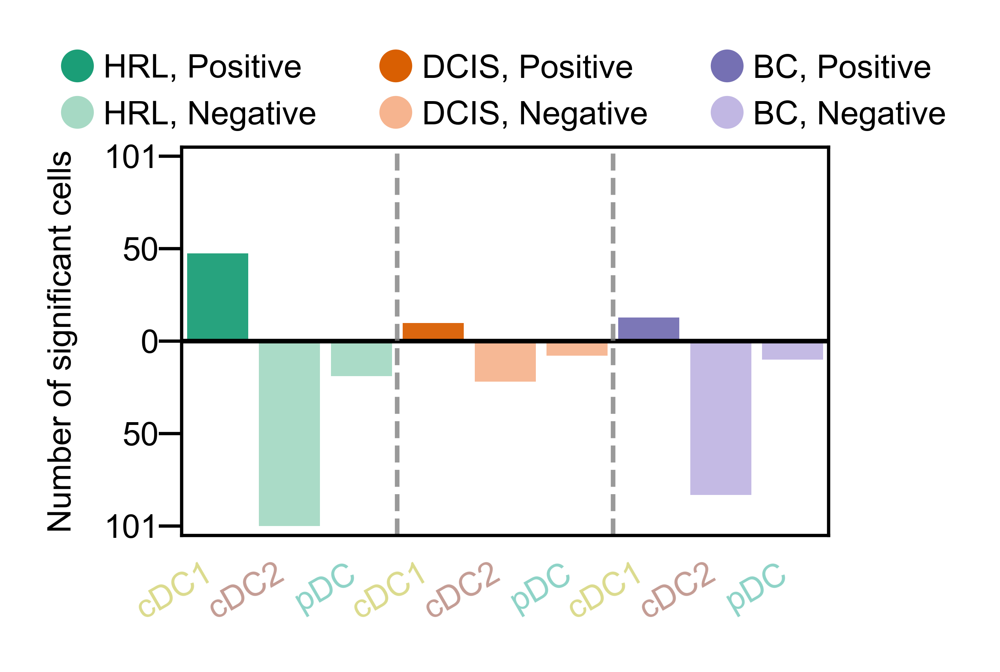

In [20]:
plot_posneg_by_stage_celltype(
    df_counts,
    covar_filter='race',
    cells_ordered=cells_ordered,
    palette_all=palette_all,
    figsize=(2,1.5
            ),
    outfile='plots/Figure6/barplot_NumSigCells_DC.svg'
)

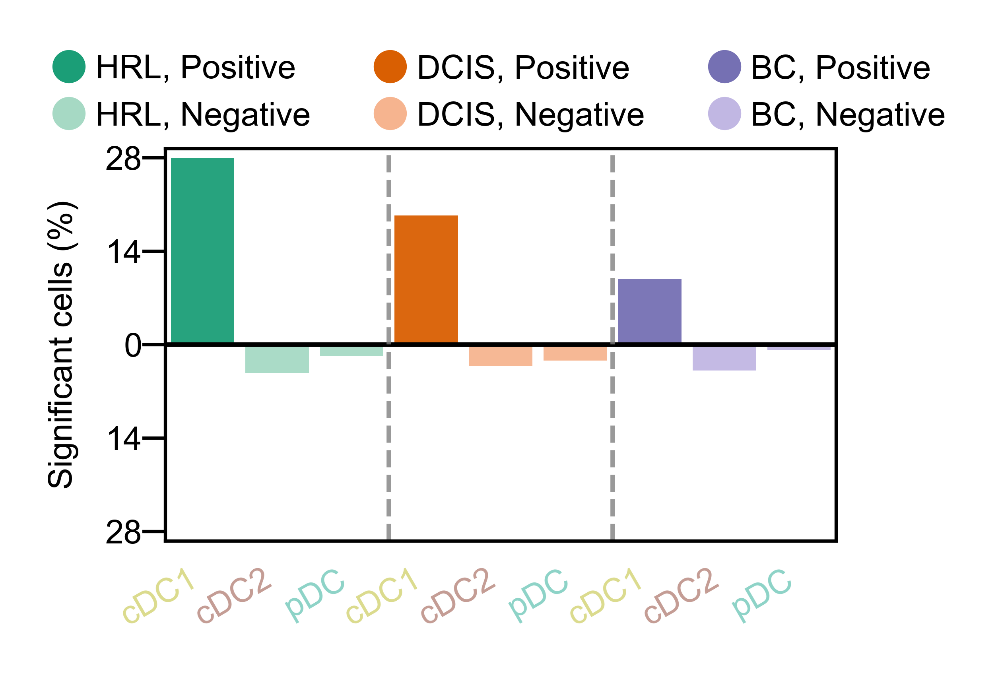

In [19]:
plot_posneg_by_stage_celltype(
    df_counts,
    covar_filter='race',
    plottype='pct',
    cells_ordered=cells_ordered,
    palette_all=palette_all,
    figsize=(2,1.5
            ),
    outfile='plots/Figure6/barplot_PctSigCells_DC.svg'
)

# Rank genes

by (Spearman corr) with neighborhood coef by race

In [20]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from scipy import sparse
from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests

def fast_spearman_ann(adata, obs_key, genes=None, chunk_size=2000, eps=1e-12):
    """
    Fast Spearman correlation between a per-cell variable (obs_key)
    and expression of each gene in adata.
    Returns a DataFrame with columns: rho, pval, fdr.
    """
    if genes is None:
        genes = adata.var_names
    X = adata[:, genes].X
    n_cells, n_genes = X.shape

    # rank-transform the covariate
    c = pd.to_numeric(adata.obs[obs_key], errors='coerce').to_numpy()
    r_c = rankdata(c, method='average')
    r_c0 = r_c - r_c.mean()
    norm_rc0 = np.linalg.norm(r_c0) + eps

    rho = np.empty(n_genes, dtype=float)

    for start in range(0, n_genes, chunk_size):
        end = min(start + chunk_size, n_genes)
        Xi = X[:, start:end]

        if sparse.issparse(Xi):
            Xi = Xi.toarray()

        # rank each gene (column) across cells
        R = np.apply_along_axis(rankdata, 0, Xi, method='average')
        R0 = R - R.mean(axis=0, keepdims=True)
        denomX = np.linalg.norm(R0, axis=0) + eps

        # Pearson on ranks = Spearman
        rho[start:end] = (R0.T @ r_c0) / (norm_rc0 * denomX)

    # --- p-values (two-sided) via t-approximation ---
    df = n_cells - 2
    # Clamp |rho| to < 1 to avoid division by zero
    rho_clamped = np.clip(rho, -1 + 1e-15, 1 - 1e-15)
    t_stat = rho_clamped * np.sqrt(df / (1 - rho_clamped**2))
    pval = 2 * student_t.sf(np.abs(t_stat), df=df)

    # --- FDR (Benjamini–Hochberg) ---
    fdr = multipletests(pval, method='fdr_bh')[1]

    out = pd.DataFrame(
        {'rho': rho, 'pval': pval, 'fdr': fdr},
        index=pd.Index(genes, name='gene')
    )
    out.name = f'spearman_{obs_key}'
    return out

In [29]:
# Example usage
res = fast_spearman_ann(d, obs_key='race_coef', genes=d.var_names, chunk_size=2000)
res.sort_values('rho', ascending=False).head()

,rho,pval,fdr
gene,,,
CADM1,0.265555,2.128211e-129,2.966620e-125
CLEC9A,0.254757,6.721534e-119,3.747793e-115
CLNK,0.236487,2.978766e-102,1.038063e-98
IDO1,0.233615,9.231587e-100,2.339704e-96
XCR1,0.228377,2.638427e-95,6.129726e-92


In [30]:
gene_corr_df = pd.DataFrame(res)
gene_corr_df.to_csv('data/Figure6/DC_all_CorrWithRace.csv')

# Exp Heatmap 
Expr of corr-selected genes

In [12]:
d = pkl.load(
         open('data/Figure6/DC_NAM_GeneModuleScored_immport.pkl', 'rb'))


In [13]:
rnk = pd.read_csv('data/Figure6/DC_all_CorrWithRace.csv') # spearman corr


rnk = rnk[rnk['fdr']<0.05] # significant only
rnk  = rnk.sort_values('rho',ascending=False).dropna()
rnk

,gene,rho,pval,fdr
11900,CADM1,0.265555,2.128211e-129,2.966620e-125
12238,CLEC9A,0.254757,6.721534e-119,3.747793e-115
4847,CLNK,0.236487,2.978766e-102,1.038063e-98
8805,IDO1,0.233615,9.231587e-100,2.339704e-96
3848,XCR1,0.228377,2.638427e-95,6.129726e-92
...,...,...,...,...
1290,S100A9,-0.249779,3.172406e-114,1.263478e-110
1296,S100A4,-0.253858,4.784330e-118,2.223039e-114
18852,FTL,-0.255816,6.606157e-120,4.604326e-116
4262,CSTA,-0.259560,1.652536e-123,1.535702e-119


In [14]:
g_up = rnk['gene'][:10]
g_dn = rnk['gene'][-10:]

/tmp/ipykernel_2772979/3950119439.py:75: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


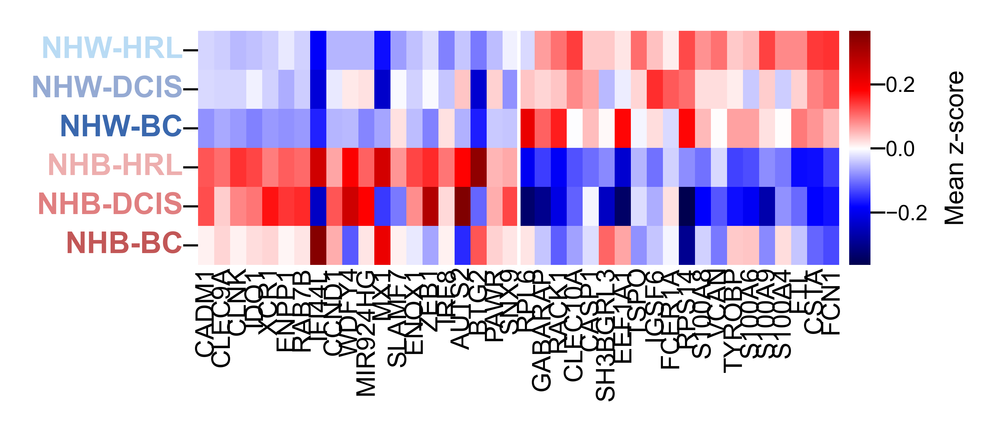

In [16]:
import numpy as np
import pandas as pd
from scipy import sparse
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# --- inputs ---
order_rows = ['NHW-HRL', 'NHW-DCIS', 'NHW-BC', 'NHB-HRL', 'NHB-DCIS', 'NHB-BC']
genes_up = list(g_up)
genes_dn = list(g_dn)
genes_all = [g for g in (genes_up + genes_dn) if g in d.var_names]  # keep order

# --- slice expression for selected genes (cells x genes) ---
X = d[:, genes_all].X
if sparse.issparse(X):
    X = X.toarray()

# --- z-score per gene across ALL patients ---
mu = X.mean(axis=0)
sigma = X.std(axis=0, ddof=0)
sigma_safe = np.where(sigma == 0, np.nan, sigma)
Z = (X - mu) / sigma_safe
Z = np.nan_to_num(Z, nan=0.0)

# --- average z-scores by race–stage group ---
zdf = pd.DataFrame(Z, index=d.obs_names, columns=genes_all)
zdf['race-stage'] = d.obs['race-stage'].astype(str).values
zmeans = (
    zdf.groupby('race-stage')[genes_all]
       .mean()
       .reindex(order_rows)  # enforce y-axis order
)

# --- flip orientation: y-axis = groups, x-axis = genes ---
mat = zmeans  # rows = groups, cols = genes

# optional: cap extreme z-scores for better visualization
mat_plot = mat.clip(lower=-3, upper=3)

# --- plot heatmap ---
fig = plt.figure(figsize=(2.8, 1))  # Adjust height as needed
gs = gridspec.GridSpec(1, 2, width_ratios=[30, 1], wspace=0.03)

ax = plt.subplot(gs[0])
cbar_ax = plt.subplot(gs[1])

sns.heatmap(
    mat_plot,
    cmap='seismic', center=0,
    cbar_ax=cbar_ax,
    cbar_kws={'label': 'Mean z-score'},
    xticklabels=True, yticklabels=True,
    ax=ax
)

ax.set_xlabel('', fontsize=8)
ax.set_ylabel('', fontsize=8)
ax.tick_params(axis='x', labelrotation=90, labelsize=6, pad=-3)
ax.tick_params(axis='y', labelsize=5, pad=0)

# Color y-axis labels
for i, tick in enumerate(ax.get_yticklabels()):
    label = order_rows[i]
    tick.set_color(palette_metadata.get(label, 'black'))
    tick.set_ha('right')
    tick.set_fontweight('bold')
    tick.set_fontsize(7)

# Add separator
sep = len([g for g in genes_up if g in genes_all])
if 0 < sep < len(genes_all):
    ax.vlines(sep, *ax.get_ylim(), colors='white', linewidth=0.8)

fig.tight_layout()
fig.savefig(f'plots/Figure6/{celltype_major}_heatmap_meanZ_group_rows.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

# GSEA

In [76]:
import gseapy as gp
from gseapy import barplot, dotplot
from scipy.stats import spearmanr

## Immport

In [60]:
gene_corr_df = pd.read_csv('data/Figure6/DC_all_CorrWithRace.csv',
                           index_col=0
                          )
gene_corr_df

,rho,pval,fdr
gene,,,
AL627309.1,0.008809,0.430452,0.791490
AL627309.5,0.015424,0.167450,0.456697
LINC01409,0.024323,0.029474,0.136793
LINC01128,0.029493,0.008288,0.048694
LINC00115,-0.004248,0.703798,1.000000
...,...,...,...
AC104758.2,0.000000,1.000000,1.000000
AC015660.3,0.000000,1.000000,1.000000
ZG16,0.000000,1.000000,1.000000


In [61]:
pre_res = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                     gene_sets='data/11_genesets/immport_allgenelist.gmt',
                     threads=1,
                     min_size=5,
                     max_size=1000,
                     permutation_num=1000, # reduce number to speed up testing
                     outdir=None, # don't write to disk
                     seed=1024,
                     verbose=True, # see what's going on behind the scenes
                    )


2025-08-19 16:21:56,116 [WARNING] Duplicated values found in preranked stats: 16.13% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-08-19 16:21:56,117 [INFO] Parsing data files for GSEA.............................
2025-08-19 16:21:56,150 [INFO] 0035 gene_sets have been filtered out when max_size=1000 and min_size=5
2025-08-19 16:21:56,151 [INFO] 0118 gene_sets used for further statistical testing.....
2025-08-19 16:21:56,152 [INFO] Start to run GSEA...Might take a while..................
2025-08-19 16:22:06,956 [INFO] Congratulations. GSEApy runs successfully................



In [62]:
pkl.dump(pre_res, 
         open('data/Figure6/DC_rankbyCorrToNHBrace_gsea_immport.pkl', 'wb'))

In [21]:
pre_res = pkl.load(
    open('data/Figure6/DC_rankbyCorrToNHBrace_gsea_immport.pkl', 'rb')
)

In [22]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]

dfp

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
10,prerank,COSTIMULATION BY THE CD28 FAMILY,0.5289,1.713546,0.003175,0.04942,0.108,20/67,6.42%,HLA-DQA2;BTLA;LYN;PPP2R5C;MAP3K8;THEM4;RICTOR;...
31,prerank,INTERLEUKIN-12 FAMILY SIGNALING,-0.551005,-1.541757,0.007485,0.040954,0.594,20/57,13.33%,RPLP0;ANXA2;TALDO1;CFL1;GSTO1;MSN;IL27RA;HNRNP...
30,prerank,NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR SIGN...,-0.672536,-1.545888,0.02451,0.040581,0.575,7/19,7.12%,ARRB2;IRAK3;CD300A;CD300LF;GPR108;GPS2;NFKBIL1
29,prerank,INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PA...,-0.494621,-1.554307,0.002538,0.037807,0.53,37/129,8.37%,FCN1;TYROBP;CASP1;NAIP;LILRA2;TLR2;CTSS;IRAK3;...
26,prerank,MYELOID LEUKOCYTE ACTIVATION,-0.513857,-1.582387,0.002632,0.028246,0.414,21/113,4.48%,TYROBP;LILRA2;S100A12;AIF1;FCER1G;TLR2;CX3CR1;...
25,prerank,LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY R...,-0.699402,-1.58399,0.020067,0.028911,0.41,5/18,3.86%,S100A9;S100A8;ALOX5;NINJ1;ADAM8
23,prerank,ACTIVATION OF INNATE IMMUNE RESPONSE,-0.497971,-1.595331,0.00123,0.026356,0.366,45/154,8.82%,FCN1;TYROBP;CASP1;MNDA;NAIP;LILRA2;TLR2;CTSS;I...
22,prerank,MYELOID LEUKOCYTE MIGRATION,-0.513673,-1.606254,0.00128,0.024275,0.331,25/126,7.55%,S100A9;S100A8;CSF3R;S100A12;FCER1G;ITGB2;IL17R...
21,prerank,"NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT...",-0.580243,-1.606585,0.007133,0.025327,0.329,29/56,15.58%,CASP1;RPS27A;PYCARD;TXNIP;CASP4;P2RX7;NLRP1;NL...
20,prerank,TCR SIGNALING,-0.52185,-1.618826,0.002663,0.022519,0.29,43/116,9.54%,RPS27A;FYB1;PAK1;PSMA7;NFKBIA;PSMA5;WAS;SEM1;C...


In [23]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Tag %'] = (
    dfp['Tag %']
    .astype(str)
    .apply(lambda x: eval(x) if '/' in x else float(x))
)
dfp['Tag %'] = dfp['Tag %'] * 100
dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))

# Sort by NES
dfp = dfp.sort_values('NES', ascending=False)

# filter - 
dfp = dfp[dfp['Tag %']>=30]
dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]
dfp

/tmp/ipykernel_3385000/346648306.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p
31,prerank,INTERLEUKIN-12 FAMILY SIGNALING,-0.551005,-1.541757,0.007485,0.040954,0.594,35.087719,13.33%,RPLP0;ANXA2;TALDO1;CFL1;GSTO1;MSN;IL27RA;HNRNP...,2.125806
30,prerank,NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR SIGN...,-0.672536,-1.545888,0.02451,0.040581,0.575,36.842105,7.12%,ARRB2;IRAK3;CD300A;CD300LF;GPR108;GPS2;NFKBIL1,1.610660
21,prerank,"NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT...",-0.580243,-1.606585,0.007133,0.025327,0.329,51.785714,15.58%,CASP1;RPS27A;PYCARD;TXNIP;CASP4;P2RX7;NLRP1;NL...,2.146748
20,prerank,TCR SIGNALING,-0.52185,-1.618826,0.002663,0.022519,0.29,37.068966,9.54%,RPS27A;FYB1;PAK1;PSMA7;NFKBIA;PSMA5;WAS;SEM1;C...,2.574610
18,prerank,INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE...,-0.565378,-1.627052,0.00561,0.022252,0.264,34.426230,11.52%,FCN1;TYROBP;LILRA2;TLR2;PAK1;NFKBIA;TLR5;CD14;...,2.251030
17,prerank,SIGNALING BY THE B CELL RECEPTOR (BCR),-0.531017,-1.631544,0.001351,0.021824,0.25,40.540541,10.61%,RPS27A;PSMA7;FKBP1A;NFKBIA;PSMA5;PTPN6;SEM1;PS...,2.869232
14,prerank,LEUKOCYTE MEDIATED CYTOTOXICITY,-0.591598,-1.673789,0.002899,0.014176,0.144,31.147541,7.70%,FCGR2B;CD2;LYST;CTSH;STXBP2;HCST;FCGR2A;P2RX7;...,2.537819
13,prerank,INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS,-0.649486,-1.684133,0.003125,0.013561,0.128,34.285714,10.62%,FCER1A;FCGR2B;FCGR2A;IL1RN;CD68;HMGB2;RBPJ;FCG...,2.505150
12,prerank,ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE,-0.735263,-1.701749,0.001603,0.011463,0.098,30.000000,8.64%,RNASE2;RPL39;FAU;NOD2;IL6R;RNASE3,2.795185
9,prerank,FC EPSILON RECEPTOR (FCERI) SIGNALING,-0.561429,-1.746881,0.0,0.005508,0.042,40.151515,10.73%,FCER1A;FCER1G;RPS27A;LAT2;FOS;JUN;PAK1;PSMA7;R...,300.000000


In [24]:
for term in dfp['Term']:
    print(term)

INTERLEUKIN-12 FAMILY SIGNALING
NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR SIGNALING PATHWAY
NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS
TCR SIGNALING
INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY
SIGNALING BY THE B CELL RECEPTOR (BCR)
LEUKOCYTE MEDIATED CYTOTOXICITY
INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS
ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE
FC EPSILON RECEPTOR (FCERI) SIGNALING
INNATE IMMUNE RESPONSE IN MUCOSA
ROS AND RNS PRODUCTION IN PHAGOCYTES
INTERLEUKIN-1 FAMILY SIGNALING
C-TYPE LECTIN RECEPTORS (CLRS)
TNFR2 NON-CANONICAL NF-KB PATHWAY
NEUTROPHIL DEGRANULATION


In [25]:
terms_sel = [
'INTERLEUKIN-12 FAMILY SIGNALING',
'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR SIGNALING PATHWAY',
'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS',
# 'TCR SIGNALING',
'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
# 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
# 'LEUKOCYTE MEDIATED CYTOTOXICITY',
'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
# 'FC EPSILON RECEPTOR (FCERI) SIGNALING',
# 'INNATE IMMUNE RESPONSE IN MUCOSA',
# 'ROS AND RNS PRODUCTION IN PHAGOCYTES',
'INTERLEUKIN-1 FAMILY SIGNALING',
'C-TYPE LECTIN RECEPTORS (CLRS)',
'TNFR2 NON-CANONICAL NF-KB PATHWAY'#,
# 'NEUTROPHIL DEGRANULATION'   
]

/tmp/ipykernel_3385000/3302113811.py:78: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  plt.draw()
/tmp/ipykernel_3385000/3302113811.py:79: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  plt.savefig(f"plots/Figure6/{celltype_major}_{group_label}_GSEA_immport.png", dpi=600, bbox_inches='tight')
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


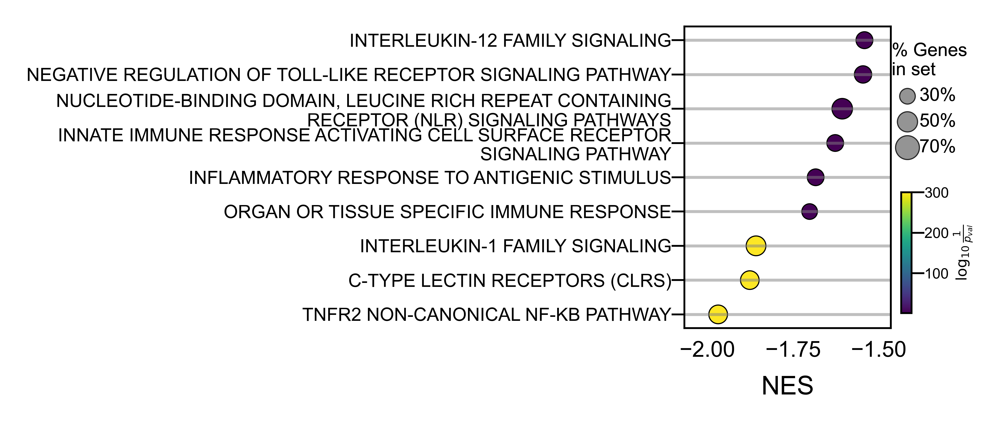

In [29]:
group_label = 'All'

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from textwrap import fill

# Parameters
dot_scale = 0.6
cmap = cm.viridis
wrap_width = 60  # number of characters before wrapping a label

# Wrap long term names for y-axis
dfp_plot = dfp[dfp['Term'].isin(terms_sel)].copy() # no term selection
dfp_plot['Term_wrapped'] = dfp_plot['Term'].apply(lambda x: fill(x, width=wrap_width))

# Plot setup
fig, ax = plt.subplots(figsize=(1, 1.5
                               ), constrained_layout=True)  # wider if needed for long labels
sc = ax.scatter(
    dfp_plot['NES'],
    dfp_plot['Term_wrapped'],
    s=dfp_plot['Tag %'] * dot_scale,
    c=dfp_plot['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()

# Axis labels
nes_max = dfp_plot['NES'].max()
pad = nes_max * 0.01
nes_min = dfp_plot['NES'].min()
ax.set_xlim([nes_min * 1.05, nes_max * .95])


ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=6)
ax.tick_params(axis='y', labelsize=5)
ax.set_title('', fontsize=7, pad=4)

ax.axvline(x=0, linestyle='--', color='gray')
# Horizontal gridlines
ax.grid(axis='y', linestyle='-', color='gray', alpha=0.5)


# Colorbar inset
axins = inset_axes(ax,
                   width="5%",
                   height="40%",
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
cbar.set_label(r"$\log_{10}\frac{1}{p_{val}}$", fontsize=4, labelpad=1)
cbar.ax.tick_params(labelsize=4)

# Dot size legend
for size in [30, 50, 70]:
    ax.scatter([], [], s=size * dot_scale, c='gray', alpha=0.6,
               edgecolor='black', linewidth=0.3, label=f"{size}%")

leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5,
    fontsize=5, frameon=False,
    loc='upper right', bbox_to_anchor=(1.45, 1)
)
ax.add_artist(leg1)

# Layout & save
plt.draw() 
plt.savefig(f"plots/Figure6/{celltype_major}_{group_label}_GSEA_immport.png", dpi=600, bbox_inches='tight')
plt.show()

In [28]:
nes_min

-2.3908264633297005

## Hallmark

In [34]:
gene_corr_df = pd.read_csv('data/Figure6/DC_all_CorrWithRace.csv',
                           index_col=0
                          )
gene_corr_df

,rho,pval,fdr
gene,,,
AL627309.1,0.008809,0.430452,0.791490
AL627309.5,0.015424,0.167450,0.456697
LINC01409,0.024323,0.029474,0.136793
LINC01128,0.029493,0.008288,0.048694
LINC00115,-0.004248,0.703798,1.000000
...,...,...,...
AC104758.2,0.000000,1.000000,1.000000
AC015660.3,0.000000,1.000000,1.000000
ZG16,0.000000,1.000000,1.000000


In [52]:
pre_res = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                     gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                     threads=1,
                     min_size=5,
                     max_size=1000,
                     permutation_num=1000, # reduce number to speed up testing
                     outdir=None, # don't write to disk
                     seed=1024,
                     verbose=True, # see what's going on behind the scenes
                    )


2025-08-19 16:20:24,974 [WARNING] Duplicated values found in preranked stats: 16.13% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-08-19 16:20:24,975 [INFO] Parsing data files for GSEA.............................
2025-08-19 16:20:25,009 [INFO] 0000 gene_sets have been filtered out when max_size=1000 and min_size=5
2025-08-19 16:20:25,010 [INFO] 0050 gene_sets used for further statistical testing.....
2025-08-19 16:20:25,011 [INFO] Start to run GSEA...Might take a while..................
2025-08-19 16:20:30,364 [INFO] Congratulations. GSEApy runs successfully................



In [53]:
pkl.dump(pre_res, 
         open('data/Figure6/DC_rankbyCorrToNHBrace_gsea_hallmark.pkl', 'wb'))

In [35]:
pre_res = pkl.load(
    open('data/Figure6/DC_rankbyCorrToNHBrace_gsea_hallmark.pkl', 'rb')
)

In [36]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]

dfp

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
6,prerank,INTERFERON GAMMA RESPONSE,0.453767,1.737172,0.0,0.006287,0.006,67/196,7.88%,IDO1;IFI44L;MX1;SLAMF7;IRF8;AUTS2;PDE4B;P2RY14...
7,prerank,INTERFERON ALPHA RESPONSE,0.497844,1.722838,0.0,0.004715,0.009,42/96,9.80%,IFI44L;MX1;IFITM1;IRF7;IFIT3;TAP1;ISG20;NCOA7;...
8,prerank,KRAS SIGNALING DN,0.445736,1.650502,0.0,0.006986,0.02,30/155,13.50%,IFI44L;MX1;BTG2;THRB;TENT5C;SIDT1;ENTPD7;CD207...
19,prerank,MITOTIC SPINDLE,0.382572,1.446586,0.005181,0.040866,0.138,64/199,12.40%,NET1;ARHGAP5;CD2AP;FLNB;AKAP13;RICTOR;NEDD9;DS...
20,prerank,KRAS SIGNALING UP,-0.437341,-1.419993,0.008516,0.039953,0.483,38/185,8.54%,F13A1;GLRX;FCER1G;ITGB2;CTSS;LAT2;TMEM176B;CLE...
18,prerank,APOPTOSIS,-0.475226,-1.509197,0.003764,0.015526,0.221,44/155,8.62%,TSPO;CASP1;DPYD;TIMP1;LGALS3;GSN;CD2;GPX4;ANXA...
17,prerank,HYPOXIA,-0.471507,-1.528045,0.001233,0.013078,0.186,43/189,8.19%,S100A4;GAPDH;ANXA2;ALDOA;GLRX;BTG1;TPI1;FOS;PG...
16,prerank,MYC TARGETS V2,-0.53883,-1.539769,0.012748,0.012322,0.166,22/57,12.82%,HK2;SLC19A1;SRM;WDR74;AIMP2;FARSA;IMP4;EXOSC5;...
15,prerank,GLYCOLYSIS,-0.47845,-1.558511,0.002387,0.010844,0.136,54/192,12.09%,VCAN;ALDOA;GLRX;TALDO1;PYGL;IL13RA1;TPI1;PGAM1...
14,prerank,XENOBIOTIC METABOLISM,-0.484355,-1.571461,0.001232,0.010269,0.12,65/181,15.17%,BLVRB;TMEM176B;CD36;CES1;CA2;ETS2;GSTO1;ECH1;F...


In [37]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Tag %'] = (
    dfp['Tag %']
    .astype(str)
    .apply(lambda x: eval(x) if '/' in x else float(x))
)
dfp['Tag %'] = dfp['Tag %'] * 100
dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))

# Sort by NES
dfp = dfp.sort_values('NES', ascending=False)

# filter - 
dfp = dfp[dfp['Tag %']>=30]
dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]
dfp

/tmp/ipykernel_2772979/346648306.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p
6,prerank,INTERFERON GAMMA RESPONSE,0.453767,1.737172,0.0,0.006287,0.006,34.183673,7.88%,IDO1;IFI44L;MX1;SLAMF7;IRF8;AUTS2;PDE4B;P2RY14...,300.000000
7,prerank,INTERFERON ALPHA RESPONSE,0.497844,1.722838,0.0,0.004715,0.009,43.750000,9.80%,IFI44L;MX1;IFITM1;IRF7;IFIT3;TAP1;ISG20;NCOA7;...,300.000000
19,prerank,MITOTIC SPINDLE,0.382572,1.446586,0.005181,0.040866,0.138,32.160804,12.40%,NET1;ARHGAP5;CD2AP;FLNB;AKAP13;RICTOR;NEDD9;DS...,2.285557
16,prerank,MYC TARGETS V2,-0.53883,-1.539769,0.012748,0.012322,0.166,38.596491,12.82%,HK2;SLC19A1;SRM;WDR74;AIMP2;FARSA;IMP4;EXOSC5;...,1.894562
14,prerank,XENOBIOTIC METABOLISM,-0.484355,-1.571461,0.001232,0.010269,0.12,35.911602,15.17%,BLVRB;TMEM176B;CD36;CES1;CA2;ETS2;GSTO1;ECH1;F...,2.909556
13,prerank,MTORC1 SIGNALING,-0.481206,-1.580211,0.0,0.010127,0.109,30.102041,11.71%,GAPDH;IFI30;CORO1A;ALDOA;GLRX;SERP1;CFP;ITGB2;...,300.000000
12,prerank,P53 PATHWAY,-0.487286,-1.582371,0.0,0.010646,0.104,32.291667,11.63%,S100A4;CASP1;RACK1;IFI30;RPL18;CEBPA;BTG1;TXNI...,300.000000
11,prerank,ALLOGRAFT REJECTION,-0.495622,-1.613541,0.001239,0.008434,0.075,30.366492,10.34%,IGSF6;CAPG;CD1D;CFP;TLR2;RPL39;RPS3A;ITGB2;CTS...,2.906874
9,prerank,UV RESPONSE UP,-0.515756,-1.641808,0.001274,0.006478,0.045,38.815789,13.88%,ALDOA;ARRB2;BTG1;ATP6V1F;FOS;CA2;RHOB;AP2S1;PR...,2.894870
5,prerank,DNA REPAIR,-0.549497,-1.767455,0.0,0.000821,0.005,42.953020,13.82%,GPX4;APRT;POLR2E;SUPT4H1;GTF2A2;PNP;POLE4;SDCB...,300.000000


In [38]:
for term in dfp['Term']:
    print(term)

INTERFERON GAMMA RESPONSE
INTERFERON ALPHA RESPONSE
MITOTIC SPINDLE
MYC TARGETS V2
XENOBIOTIC METABOLISM
MTORC1 SIGNALING
P53 PATHWAY
ALLOGRAFT REJECTION
UV RESPONSE UP
DNA REPAIR
ADIPOGENESIS
FATTY ACID METABOLISM
REACTIVE OXYGEN SPECIES PATHWAY
MYC TARGETS V1
OXIDATIVE PHOSPHORYLATION


In [39]:
terms_sel = [
'INTERFERON GAMMA RESPONSE',
'INTERFERON ALPHA RESPONSE',
'MITOTIC SPINDLE',
'MYC TARGETS V2',
# 'XENOBIOTIC METABOLISM',
'MTORC1 SIGNALING',
'P53 PATHWAY',
'ALLOGRAFT REJECTION',
'UV RESPONSE UP',
'DNA REPAIR',
# 'ADIPOGENESIS',
'FATTY ACID METABOLISM',
'REACTIVE OXYGEN SPECIES PATHWAY',
'MYC TARGETS V1',
'OXIDATIVE PHOSPHORYLATION'
]

/tmp/ipykernel_2772979/2353674877.py:78: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  plt.draw()
/tmp/ipykernel_2772979/2353674877.py:79: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  plt.savefig(f"plots/Figure6/{celltype_major}_{group_label}_GSEA_hallmark.png", dpi=600, bbox_inches='tight')
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


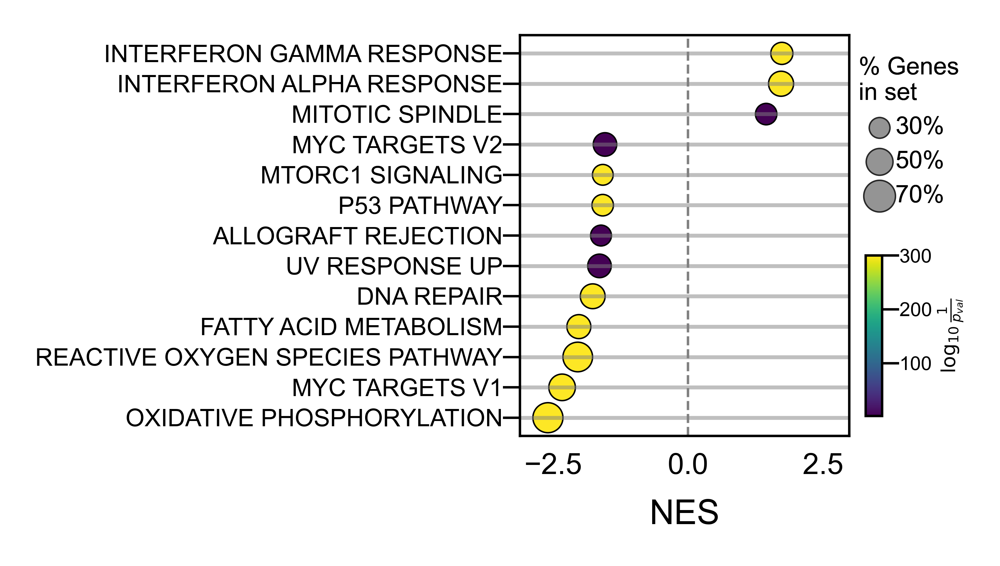

In [40]:
group_label = 'All'

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from textwrap import fill

# Parameters
dot_scale = 0.6
cmap = cm.viridis
wrap_width = 40  # number of characters before wrapping a label

# Wrap long term names for y-axis
dfp_plot = dfp[dfp['Term'].isin(terms_sel)].copy() # no term selection
dfp_plot['Term_wrapped'] = dfp_plot['Term'].apply(lambda x: fill(x, width=wrap_width))

# Plot setup
fig, ax = plt.subplots(figsize=(1.2, 1.5
                               ), constrained_layout=True)  # wider if needed for long labels
sc = ax.scatter(
    dfp_plot['NES'],
    dfp_plot['Term_wrapped'],
    s=dfp_plot['Tag %'] * dot_scale,
    c=dfp_plot['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()

# Axis labels
nes_max = dfp['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp['NES'].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.15])


ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=6)
ax.tick_params(axis='y', labelsize=5)
ax.set_title('', fontsize=7, pad=4)

ax.axvline(x=0, linestyle='--', color='gray')
# Horizontal gridlines
ax.grid(axis='y', linestyle='-', color='gray', alpha=0.5)


# Colorbar inset
axins = inset_axes(ax,
                   width="5%",
                   height="40%",
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
cbar.set_label(r"$\log_{10}\frac{1}{p_{val}}$", fontsize=4, labelpad=1)
cbar.ax.tick_params(labelsize=4)

# Dot size legend
for size in [30, 50, 70]:
    ax.scatter([], [], s=size * dot_scale, c='gray', alpha=0.6,
               edgecolor='black', linewidth=0.3, label=f"{size}%")

leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5,
    fontsize=5, frameon=False,
    loc='upper right', bbox_to_anchor=(1.4, 1)
)
ax.add_artist(leg1)

# Layout & save
plt.draw() 
plt.savefig(f"plots/Figure6/{celltype_major}_{group_label}_GSEA_hallmark.png", dpi=600, bbox_inches='tight')
plt.show()

# Gene Module Scores

## Immport

In [20]:
gset = read_gmt('data/11_genesets/immport_allgenelist.gmt')

In [21]:
gset = {k.upper(): v for k, v in gset.items()}

In [24]:
terms_sel = [
'INTERLEUKIN-12 FAMILY SIGNALING',
'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR SIGNALING PATHWAY',
'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS',
# 'TCR SIGNALING',
'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
# 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
# 'LEUKOCYTE MEDIATED CYTOTOXICITY',
'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
# 'FC EPSILON RECEPTOR (FCERI) SIGNALING',
# 'INNATE IMMUNE RESPONSE IN MUCOSA',
# 'ROS AND RNS PRODUCTION IN PHAGOCYTES',
'INTERLEUKIN-1 FAMILY SIGNALING',
'C-TYPE LECTIN RECEPTORS (CLRS)',
'TNFR2 NON-CANONICAL NF-KB PATHWAY'#,
# 'NEUTROPHIL DEGRANULATION'   
]

In [25]:
import scanpy as sc

for pathway in terms_sel:

    gene_list = gset[pathway]
    pathway_newname = pathway.removeprefix('hallmark_').replace('_',' ').upper()

    sc.tl.score_genes(d, gene_list, 
                  score_name=pathway_newname
                 )
    

       'H2BC11', 'H2BC12', 'H2BC12L', 'H2BC21', 'H2BC4', 'H2BC6', 'H2BC7',
       'H2BC8', 'IFNL2', 'UMOD'],
      dtype='object')


In [26]:
pkl.dump(d, 
         open('data/Figure6/DC_NAM_GeneModuleScored_immport.pkl', 'wb'))

In [27]:
d = pkl.load(
    open('data/Figure6/DC_NAM_GeneModuleScored_immport.pkl', 'rb')
)
d

AnnData object with n_obs × n_vars = 8012 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3', 'sampleid', 'age', 'race-stage', 'race', 'group', 'diabetes', 'obesity', 'race_coef', 'race_coef_fdr', 'INTERLEUKIN-12 FAMILY SIGNALING', 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR SIGNALING PATHWAY', 'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS', 'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY', 'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS', 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE', 'INTERL

In [28]:
Counter(d.obs['race-stage'])

Counter({'NHW-HRL': 1986,
         'NHW-BC': 1913,
         'NHB-HRL': 1574,
         'NHB-BC': 1488,
         'NHW-DCIS': 758,
         'NHB-DCIS': 293})

In [29]:
celltype_major

'DC'

/tmp/ipykernel_1496183/2976973335.py:62: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub['race-stage'] = pd.Categorical(
/tmp/ipykernel_1496183/2976973335.py:92: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby('race-stage')[yname].median()#.sort_values(ascending=False)
/tmp/ipykernel_1496183/2976973335.py:62: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas


TNFR2 NON-CANONICAL NF-KB PATHWAY cDC1
race-stage
NHW-HRL     0.307531
NHB-HRL     0.301640
NHW-DCIS    0.331413
NHB-DCIS    0.291292
NHW-BC      0.299194
NHB-BC      0.291734
Name: TNFR2 NON-CANONICAL NF-KB PATHWAY, dtype: float64
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided, P_val:1.662e-02 U_stat=4.070e+02

TNFR2 NON-CANONICAL NF-KB PATHWAY cDC2
race-stage
NHW-HRL     0.287639
NHB-HRL     0.273624
NHW-DCIS    0.289838
NHB-DCIS    0.273286
NHW-BC      0.299843
NHB-BC      0.285460
Name: TNFR2 NON-CANONICAL NF-KB PATHWAY, dtype: float64
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-side

/tmp/ipykernel_1496183/2976973335.py:92: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby('race-stage')[yname].median()#.sort_values(ascending=False)


NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided, P_val:6.202e-04 U_stat=5.228e+04
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided, P_val:1.557e-09 U_stat=6.327e+05

TNFR2 NON-CANONICAL NF-KB PATHWAY pDC
race-stage
NHW-HRL     0.257076
NHB-HRL     0.265218
NHW-DCIS    0.257882
NHB-DCIS    0.229063
NHW-BC      0.273185
NHB-BC      0.268185
Name: TNFR2 NON-CANONICAL NF-KB PATHWAY, dtype: float64


/tmp/ipykernel_1496183/2976973335.py:62: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub['race-stage'] = pd.Categorical(
/tmp/ipykernel_1496183/2976973335.py:92: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby('race-stage')[yname].median()#.sort_values(ascending=False)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided, P_val:4.672e-03 U_stat=1.278e+05
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided, P_val:3.706e-03 U_stat=1.320e+04


/tmp/ipykernel_1496183/2976973335.py:62: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub['race-stage'] = pd.Categorical(
/tmp/ipykernel_1496183/2976973335.py:92: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby('race-stage')[yname].median()#.sort_values(ascending=False)
/tmp/ipykernel_1496183/2976973335.py:62: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas


C-TYPE LECTIN RECEPTORS (CLRS) cDC1
race-stage
NHW-HRL     0.361004
NHB-HRL     0.356888
NHW-DCIS    0.356997
NHB-DCIS    0.351592
NHW-BC      0.344732
NHB-BC      0.341634
Name: C-TYPE LECTIN RECEPTORS (CLRS), dtype: float64
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04


C-TYPE LECTIN RECEPTORS (CLRS) cDC2
race-stage
NHW-HRL     0.367402
NHB-HRL     0.357586
NHW-DCIS    0.365992
NHB-DCIS    0.347804
NHW-BC      0.369686
NHB-BC      0.354997
Name: C-TYPE LECTIN RECEPTORS (CLRS), dtype: float64
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided, P_val:1.695e-08 U_stat=7.456e+05
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided, P_val:9.5

/tmp/ipykernel_1496183/2976973335.py:62: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub['race-stage'] = pd.Categorical(
/tmp/ipykernel_1496183/2976973335.py:92: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby('race-stage')[yname].median()#.sort_values(ascending=False)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided, P_val:1.165e-10 U_stat=1.096e+05
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided, P_val:3.977e-02 U_stat=1.759e+05


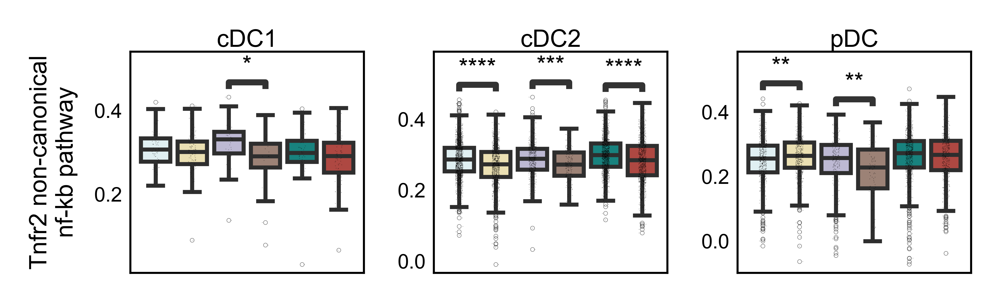

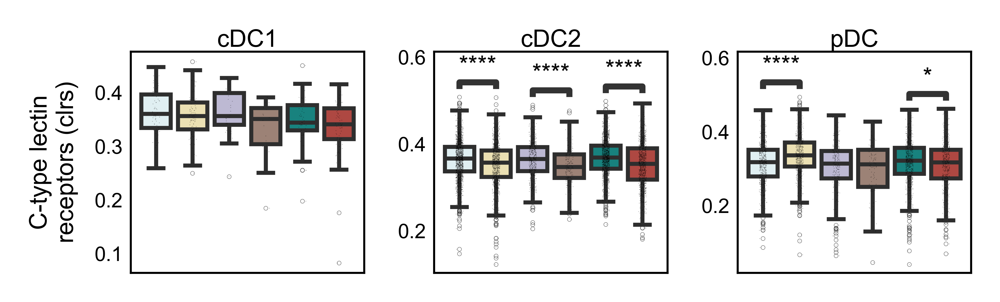

In [34]:
from statannotations.Annotator import Annotator

dfp = d.obs

dfp.head(3)

color_set = {
    'NHW-HRL':'#DDF1F5',
    'NHW-DCIS':'#BAB4D8',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F4E6AA',
    'NHB-DCIS':'#A28070',
    'NHB-BC':'#C03830'
# 
# 'Diabetes':'#F472B6',
# 'Obesity':'#F59E42'

}

group_palette = {
    'HRL': '#F5C16C',   # light gold
    'DCIS': '#EA7D30',  # orange
    'BC': '#7A491A',    # deep brown (darkest)
}

# Mapping from tick positions (0-based index) to group labels
tick_groups = {
    (0, 1): 'HRL',
    (2, 3): 'DCIS',
    (4, 5): 'BC'
}


celltypes = cells_group[celltype_major]
ynames = ['TNFR2 NON-CANONICAL NF-KB PATHWAY',
'C-TYPE LECTIN RECEPTORS (CLRS)']



for yname in ynames:
    
    ct = -1

    fig, axs = plt.subplots(figsize=(3.7,1), 
                        ncols=3, nrows=1, 
                        sharex=True, sharey=False)

    fig.subplots_adjust(wspace=0.3)
    
    for celltype in celltypes:


        ct += 1
        # if ct > 1:
        #     break
            
        ax = axs.flatten()[ct]  
        
        dfp_sub = dfp[dfp['celltype_level3']==celltype]
        
        dfp_sub['race-stage'] = pd.Categorical(
            dfp_sub['race-stage'], 
            categories=[ 
            'NHW-HRL', 'NHB-HRL',
            'NHW-DCIS', 'NHB-DCIS',
            'NHW-BC', 'NHB-BC'], 
            ordered=True
        )
                
        sns.boxplot(
            data=dfp_sub,
            x='race-stage',
            y=yname,
            hue='race-stage',
            palette=color_set,
            flierprops=dict(marker='o', markersize=.1, alpha=0.7),
            ax=ax,
            showfliers=True
        ).set_rasterized(True)  
        
        sns.stripplot(
            data=dfp_sub, x='race-stage', y=yname, size=.2, color='black', alpha=.3, ax=ax
        ).set_rasterized(True)  
        
        pairs = [
            ('NHW-HRL', 'NHB-HRL'),
            ('NHW-DCIS', 'NHB-DCIS'),
            ('NHW-BC', 'NHB-BC')
        ]

        group_stats = dfp_sub.groupby('race-stage')[yname].median()#.sort_values(ascending=False)
        print(f"\n{yname} {celltype}")
        print(group_stats)

        annotator = Annotator(
            ax, pairs, data=dfp_sub, x='race-stage', y=yname, perform_stat_test=True
        )
        
        annotator.configure(test='Mann-Whitney',text_format='star', loc='inside', hide_non_significant=True) # but I already set new p values from scanpro
        annotator.apply_and_annotate()
        
        
        
        # groupname = get_group_from_celltype(yname, cells_group)
        # title_color = major_celltype_palette.get(groupname, 'black')
        
        
        ax.set_title(celltype.replace(' Monocyte',''), fontsize=6, pad=0)
        

        ylabel = r'IFN-$\alpha$/$\beta$ signaling' if yname == 'INTERFERON ALPHA/BETA SIGNALING' else yname.lower().capitalize()        

        def wrap_ylabel(yname, width=20):
            import textwrap
            return "\n".join(textwrap.wrap(yname, width=width)).capitalize()
        
        # Example usage inside plotting code:
        ylabel = wrap_ylabel(yname.lower().capitalize(), width=20)

        if ct in [0]:
            ax.set_ylabel(ylabel, fontsize=6)  # Hide to save space
        else:
            ax.set_ylabel('', fontsize=6)


        
        ax.tick_params(axis='x', labelsize=4, rotation=90, pad=-1)
        for label in ax.get_xticklabels():
            label.set_ha('right')
        ax.tick_params(axis='y', labelsize=5, pad=2, length=0)
        ax.tick_params(axis='x', labelsize=6, pad=0, length=0)
        ax.legend([],[], frameon=False)  # Remove legend
        ax.set_xticklabels('')
        ax.set_xlabel('')

        # upper_limit = dfp_sub[yname].max()
        # ax.set_ylim(0, upper_limit * 1.1)

        # ADD colorbar at bottom
        # Find y_min so the colored bar is just below the plot
        # y_min = ax.get_ylim()[0]
        # y_offset = (ax.get_ylim()[1] - y_min) * 0.02  # a tiny offset
        
        # for (start_idx, end_idx), group in tick_groups.items():
        #     ax.axvspan(
        #         start_idx - 0.4,  # left edgeno
        #         end_idx + 0.4,    # right edge
        #         ymin=-0.02, ymax=0.0,  # relative to y-axis in axis coords
        #         color=group_palette[group],
        #         transform=ax.get_xaxis_transform(),  # align with x-axis
        #         clip_on=False,
        #         zorder=-1
        #     )
            
    plt.savefig(f'''plots/Figure6/boxplot_{celltype_major}_{yname.replace('/',' ')}_byRaceStage_immport.svg''',
                bbox_inches='tight'
               )

In [1]:
from statannotations.Annotator import Annotator

dfp = d.obs

dfp.head(3)

color_set = {
    'NHW-HRL':'#B9DBF4',
    'NHW-DCIS':'#95AAD3',
    'NHW-BC':'#3A68AE',
    
    'NHB-HRL':'#EDAEAE',
    'NHB-DCIS':'#E07F80',
    'NHB-BC':'#C25757'
# 
# 'Diabetes':'#F472B6',
# 'Obesity':'#F59E42'

}

group_palette = {
    'HRL': '#F5C16C',   # light gold
    'DCIS': '#EA7D30',  # orange
    'BC': '#7A491A',    # deep brown (darkest)
}

# Mapping from tick positions (0-based index) to group labels
tick_groups = {
    (0, 1): 'HRL',
    (2, 3): 'DCIS',
    (4, 5): 'BC'
}


celltypes = cells_group['DC']
ynames = ['TNFR2 NON-CANONICAL NF-KB PATHWAY',
'C-TYPE LECTIN RECEPTORS (CLRS)'
]

fig, axs = plt.subplots(figsize=(4,2.2), 
                        ncols=3, nrows=2, 
                        sharex=True, sharey=False)

fig.subplots_adjust(wspace=0.3, hspace=.2
                   )

ct = -1
for yname in ynames:
    
    for celltype in celltypes:


        ct += 1
        # if ct > 1:
        #     break
            
        ax = axs.flatten()[ct]  
        
        dfp_sub = dfp[dfp['celltype_level3']==celltype]
        
        dfp_sub['race-stage'] = pd.Categorical(
            dfp_sub['race-stage'], 
            categories=[ 
            'NHW-HRL', 'NHB-HRL',
            'NHW-DCIS', 'NHB-DCIS',
            'NHW-BC', 'NHB-BC'], 
            ordered=True
        )
                
        sns.boxplot(
            data=dfp_sub,
            x='race-stage',
            y=yname,
            hue='race-stage',
            palette=color_set,
            flierprops=dict(marker='o', markersize=.1, alpha=0.7),
            ax=ax,
            showfliers=True
        ).set_rasterized(True)  
        
        sns.stripplot(
            data=dfp_sub, x='race-stage', y=yname, size=.2, color='black', alpha=.3, ax=ax
        ).set_rasterized(True)  
        
        pairs = [
            ('NHW-HRL', 'NHB-HRL'),
            ('NHW-DCIS', 'NHB-DCIS'),
            ('NHW-BC', 'NHB-BC')
        ]

        group_stats = dfp_sub.groupby('race-stage')[yname].median()#.sort_values(ascending=False)
        print(f"\n{yname} {celltype}")
        print(group_stats)

        annotator = Annotator(
            ax, pairs, data=dfp_sub, x='race-stage', y=yname, perform_stat_test=True
        )
        
        annotator.configure(test='Mann-Whitney',text_format='star', loc='inside', hide_non_significant=True) # but I already set new p values from scanpro
        annotator.apply_and_annotate()
        
        
        
        # groupname = get_group_from_celltype(yname, cells_group)
        # title_color = major_celltype_palette.get(groupname, 'black')
        
        
        ax.set_title(celltype.replace(' Monocyte',''), fontsize=6, pad=0)
        ax.set_xlabel('')

        ylabel = 'TNFR2\nNon-canonical NF-κB' if ct==0 else 'C-type lectin receptors'        
        if ct in [0,3]:
            ax.set_ylabel(ylabel, fontsize=6)  # Hide to save space
        else:
            ax.set_ylabel('', fontsize=6)

        ax.set_xticklabels('')
        ax.tick_params(axis='x', labelsize=4, rotation=90, pad=-1)
        for label in ax.get_xticklabels():
            label.set_ha('right')
        ax.tick_params(axis='y', labelsize=5, pad=2, length=0)
        ax.tick_params(axis='x', labelsize=6, pad=0, length=0)
        ax.legend([],[], frameon=False)  # Remove legend
        
        
        # ADD colorbar at bottom
        # Find y_min so the colored bar is just below the plot
        y_min = ax.get_ylim()[0]
        y_offset = (ax.get_ylim()[1] - y_min) * 0.02  # a tiny offset
        
        for (start_idx, end_idx), group in tick_groups.items():
            ax.axvspan(
                start_idx - 0.4,  # left edge
                end_idx + 0.4,    # right edge
                ymin=-0.02, ymax=0.0,  # relative to y-axis in axis coords
                color=group_palette[group],
                transform=ax.get_xaxis_transform(),  # align with x-axis
                clip_on=False,
                zorder=-1
            )
            
plt.savefig(f'plots/Figure6/boxplot_DC_byRaceStage_immport.svg',
            bbox_inches='tight'
           )

NameError: name 'd' is not defined

## Hallmark

In [36]:
hallmark = read_gmt('data/11_genesets/h.all.v2024.1.Hs.symbols.gmt')
hallmark.keys()

dict_keys(['hallmark_adipogenesis', 'hallmark_allograft_rejection', 'hallmark_androgen_response', 'hallmark_angiogenesis', 'hallmark_apical_junction', 'hallmark_apical_surface', 'hallmark_apoptosis', 'hallmark_bile_acid_metabolism', 'hallmark_cholesterol_homeostasis', 'hallmark_coagulation', 'hallmark_complement', 'hallmark_dna_repair', 'hallmark_e2f_targets', 'hallmark_epithelial_mesenchymal_transition', 'hallmark_estrogen_response_early', 'hallmark_estrogen_response_late', 'hallmark_fatty_acid_metabolism', 'hallmark_g2m_checkpoint', 'hallmark_glycolysis', 'hallmark_hedgehog_signaling', 'hallmark_heme_metabolism', 'hallmark_hypoxia', 'hallmark_il2_stat5_signaling', 'hallmark_il6_jak_stat3_signaling', 'hallmark_inflammatory_response', 'hallmark_interferon_alpha_response', 'hallmark_interferon_gamma_response', 'hallmark_kras_signaling_dn', 'hallmark_kras_signaling_up', 'hallmark_mitotic_spindle', 'hallmark_mtorc1_signaling', 'hallmark_myc_targets_v1', 'hallmark_myc_targets_v2', 'hallmar

In [37]:
import scanpy as sc

for pathway,gene_list in hallmark.items():

    pathway_newname = pathway.removeprefix('hallmark_').replace('_',' ').upper()

    sc.tl.score_genes(d, gene_list, 
                  score_name=pathway_newname
                 )
    

       'WARS1'],
      dtype='object')
       'FLNC', 'KRT31', 'NHERF4', 'NRAP', 'PALS1'],
      dtype='object')
       'MBL2', 'MMP10', 'MMP3', 'MMP7', 'MMP8'],
      dtype='object')
       'MATN3', 'MMP3', 'MXRA5', 'POSTN', 'RGS4', 'SFRP1', 'SNAI2', 'WNT5A'],
      dtype='object')
       'NHERF1', 'NPY1R', 'PDLIM3', 'SLC7A2', 'SOX3', 'STC2', 'TFAP2C', 'TFF1',
       'TFF3'],
      dtype='object')
       'HMGCS2', 'KLK11', 'KRT13', 'KRT19', 'NHERF1', 'NPY1R', 'PCP4',
       'PDLIM3', 'SERPINA3', 'SERPINA5', 'SOX3', 'TFAP2C', 'TFF1', 'TFF3',
       'TH', 'TRIM29'],
      dtype='object')
       'H2AZ1', 'HAO2', 'HMGCS2', 'MIX23'],
      dtype='object')
       'PKP1', 'STC1', 'STC2'],
      dtype='object')
       'CALML5', 'CLDN8', 'CLPS', 'CNTFR', 'CPA2', 'CYP11B2', 'FGF16', 'FSHB',
       'GDNF', 'GP2', 'HTR1B', 'HTR1D', 'INSL5', 'IRS4', 'KLK7', 'KLK8',
       'KRT13', 'KRT15', 'KRT4', 'LGALS7', 'MACROH2A2', 'MYH7', 'NGB', 'NPY4R',
       'NTF3', 'PAX3', 'PAX4', 'PCDHB1', 'PKP1', 'SCN1

In [39]:
pkl.dump(d, 
         open('data/Figure6/DC_NAM_GeneModuleScored_immportAndHallmark.pkl', 'wb'))

In [8]:
d = pkl.load(
         open('data/Figure6/DC_NAM_GeneModuleScored_immportAndHallmark.pkl', 'rb'))

d

AnnData object with n_obs × n_vars = 8012 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3', 'sampleid', 'age', 'race-stage', 'race', 'group', 'diabetes', 'obesity', 'race_coef', 'race_coef_fdr', 'INTERLEUKIN-12 FAMILY SIGNALING', 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR SIGNALING PATHWAY', 'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS', 'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY', 'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS', 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE', 'INTERL

In [41]:
dfp = d.obs

dfp.head(3)

,nFeaturess_RNA,nFeaturess_RNA_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublets_score,nCount_RNA,nFeature_RNA,percent.mt,predicted.celltype.l1.score,...,PROTEIN SECRETION,REACTIVE OXYGEN SPECIES PATHWAY,SPERMATOGENESIS,TGF BETA SIGNALING,TNFA SIGNALING VIA NFKB,UNFOLDED PROTEIN RESPONSE,UV RESPONSE DN,UV RESPONSE UP,WNT BETA CATENIN SIGNALING,XENOBIOTIC METABOLISM
Pool137_10_AAACCTGGTTGGTGGA-1,2917.0,2916,10821.0,242.0,2.236392,0.052017,10821.0,2916.0,2.236392,1.0,...,0.148415,0.359806,-0.062306,0.211942,0.277981,0.245820,0.053350,0.176502,-0.065538,0.048855
Pool137_10_AAAGTAGCAGGGATTG-1,3209.0,3208,11922.0,341.0,2.860258,0.042320,11922.0,3208.0,2.860258,1.0,...,0.145974,0.343166,-0.067104,0.273080,0.395982,0.237166,0.077639,0.179703,-0.032787,0.021737
Pool137_10_AACCATGAGTGTTTGC-1,2667.0,2665,9307.0,196.0,2.105942,0.035485,9307.0,2665.0,2.105942,1.0,...,0.154876,0.247203,-0.063268,0.251732,0.233033,0.213130,0.041497,0.114983,-0.010305,0.030068


/tmp/ipykernel_126455/867744166.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub['race-stage'] = pd.Categorical(
/tmp/ipykernel_126455/867744166.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub['race-stage'] = pd.Categorical(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided, P_val:1.372e-04 U_stat=5.948e+05
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided, P_val:3.351e-03 U_stat=5.080e+05


/tmp/ipykernel_126455/867744166.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub['race-stage'] = pd.Categorical(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided, P_val:2.550e-15 U_stat=1.022e+05
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided, P_val:4.369e-08 U_stat=1.334e+05


/tmp/ipykernel_126455/867744166.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub['race-stage'] = pd.Categorical(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided, P_val:2.606e-02 U_stat=1.527e+03


/tmp/ipykernel_126455/867744166.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub['race-stage'] = pd.Categorical(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided, P_val:1.517e-03 U_stat=6.050e+05
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided, P_val:1.946e-02 U_stat=3.938e+04
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided, P_val:1.918e-02 U_stat=5.162e+05


/tmp/ipykernel_126455/867744166.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub['race-stage'] = pd.Categorical(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided, P_val:2.928e-21 U_stat=9.441e+04
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided, P_val:1.318e-03 U_stat=1.461e+05


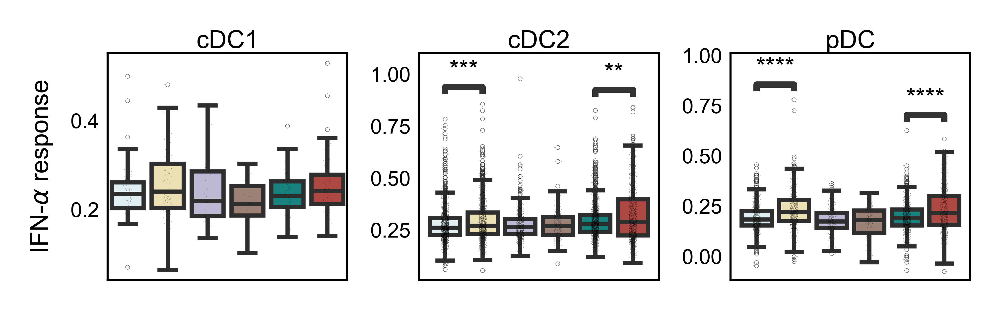

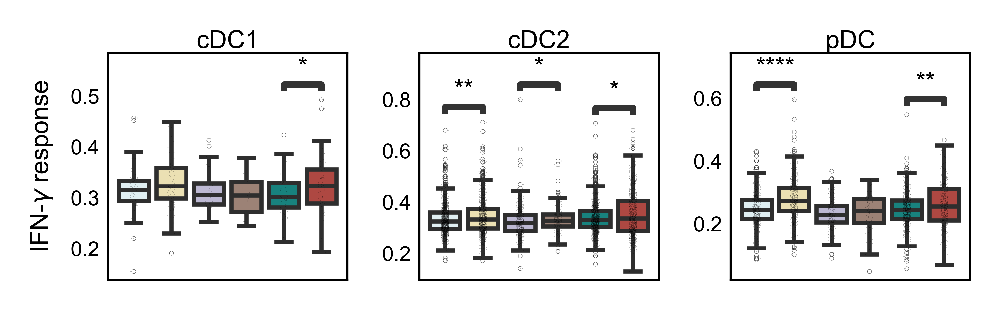

In [9]:
from statannotations.Annotator import Annotator

dfp = d.obs[['race-stage',
             'celltype_level3',
             'INTERFERON ALPHA RESPONSE',
             'INTERFERON GAMMA RESPONSE']]


dfp.head(3)

color_set = {
    'NHW-HRL':'#DDF1F5',
    'NHW-DCIS':'#BAB4D8',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F4E6AA',
    'NHB-DCIS':'#A28070',
    'NHB-BC':'#C03830'
# 
# 'Diabetes':'#F472B6',
# 'Obesity':'#F59E42'

}

group_palette = {
    'HRL': '#F5C16C',   # light gold
    'DCIS': '#EA7D30',  # orange
    'BC': '#7A491A',    # deep brown (darkest)
}

# Mapping from tick positions (0-based index) to group labels
tick_groups = {
    (0, 1): 'HRL',
    (2, 3): 'DCIS',
    (4, 5): 'BC'
}


celltypes = cells_group['DC'] #--------------- 
ynames = ['INTERFERON ALPHA RESPONSE',
          'INTERFERON GAMMA RESPONSE']



for yname in ynames:

    fig, axs = plt.subplots(figsize=(3.7, 1), ncols=3)       
    fig.subplots_adjust(wspace=0.3
                   )
    ct = -1
    for celltype in celltypes:
        
        ct += 1
        # if ct > 1:
        #     break
            
        ax = axs.flatten()[ct]  
        
        dfp_sub = dfp[dfp['celltype_level3']==celltype]
        
        dfp_sub['race-stage'] = pd.Categorical(
            dfp_sub['race-stage'], 
            categories=[ 
            'NHW-HRL', 'NHB-HRL',
            'NHW-DCIS', 'NHB-DCIS',
            'NHW-BC', 'NHB-BC'], 
            ordered=True
        )
                
        sns.boxplot(
            data=dfp_sub,
            x='race-stage',
            y=yname,
            hue='race-stage',
            palette=color_set,
            flierprops=dict(marker='o', markersize=.1, alpha=0.7),
            ax=ax,
            showfliers=True
        ).set_rasterized(True)  
        
        sns.stripplot(
            data=dfp_sub, x='race-stage', y=yname, size=.2, color='black', alpha=.3, ax=ax
        ).set_rasterized(True)  
        
        pairs = [
            ('NHW-HRL', 'NHB-HRL'),
            ('NHW-DCIS', 'NHB-DCIS'),
            ('NHW-BC', 'NHB-BC')
        ]
        
        annotator = Annotator(
            ax, pairs, data=dfp_sub, x='race-stage', y=yname, perform_stat_test=True
        )
        
        annotator.configure(test='Mann-Whitney',text_format='star', loc='inside', hide_non_significant=True) # but I already set new p values from scanpro
        annotator.apply_and_annotate()
        
        
        
        # groupname = get_group_from_celltype(yname, cells_group)
        # title_color = major_celltype_palette.get(groupname, 'black')
        
        
        ax.set_title(celltype.replace(' Monocyte',''), fontsize=6, pad=0)
        ax.set_xlabel('')

        ylabel = r'IFN-$\alpha$ response' if yname == 'INTERFERON ALPHA RESPONSE' else r'IFN-$\gamma$ response'        
        if ct in [0]:
            ax.set_ylabel(ylabel, fontsize=6)  # Hide to save space
        else:
            ax.set_ylabel('', fontsize=6)

        ax.tick_params(axis='x', labelsize=4, rotation=30, pad=-1)
        for label in ax.get_xticklabels():
            label.set_ha('right')
            
        ax.tick_params(axis='y', labelsize=5, pad=2, length=0)
        ax.set_xticklabels('')
        ax.legend([],[], frameon=False)  # Remove legend
        
        
        # ADD colorbar at bottom
        # Find y_min so the colored bar is just below the plot
        # y_min = ax.get_ylim()[0]
        # y_offset = (ax.get_ylim()[1] - y_min) * 0.02  # a tiny offset
        
        # for (start_idx, end_idx), group in tick_groups.items():
        #     ax.axvspan(
        #         start_idx - 0.4,  # left edge
        #         end_idx + 0.4,    # right edge
        #         ymin=-0.02, ymax=0.0,  # relative to y-axis in axis coords
        #         color=group_palette[group],
        #         transform=ax.get_xaxis_transform(),  # align with x-axis
        #         clip_on=False,
        #         zorder=-1
        #     )
            
    plt.savefig(f'plots/FigureS6/boxplot_DC_{yname}_byRaceStage.svg',
                bbox_inches='tight'
               )

These two axes — interferon response vs antigen-presentation maturation (via NF-κB, CLRs) — are distinct:
- Heightened IFN responsiveness could mean cells are pre-activated or tolerized.
- Suppressed maturation signals (e.g., NF-κB, CLRs) suggest functional exhaustion or dysregulation.
- Together, this pattern may suggest:
    - DCs in NHB are more inflammatory/IFN-biased
    - But less effective at antigen presentation and costimulation

# GSEA, by each stage

In [15]:
dat = pkl.load(
    open('data/Figure6/DC_NAM_GeneModuleScored_immport.pkl','rb')
)
dat

AnnData object with n_obs × n_vars = 8012 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3', 'sampleid', 'age', 'race-stage', 'race', 'group', 'diabetes', 'obesity', 'race_coef', 'race_coef_fdr', 'INTERLEUKIN-12 FAMILY SIGNALING', 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR SIGNALING PATHWAY', 'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS', 'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY', 'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS', 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE', 'INTERL

## HRL

In [90]:
celltype_major = 'DC'
group_name = 0
group_label = 'HRL'

In [17]:
d_sub = dat[
    (dat.obs['predicted.celltype.l1']==celltype_major) &
    (dat.obs['group']==group_name)
    ]

In [18]:
import scanpy as sc

sc.pp.neighbors(d_sub)


samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                               ['race','age','obesity','diabetes'],     # the metadata columns to use
                               'dataset_name')                        # the column of d.obs that contains sample IDs

samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]



res = cna.tl.association(
    d_sub,
    samplem.race, 
    'dataset_name',
    covs=samplem[['age','obesity','diabetes']],
    batches=samplem.batch,
    key_added='race_coef',
    return_full=True
)

/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

In [23]:
res = fast_spearman_ann(d_sub, 
                        obs_key='race_coef', 
                        genes=d_sub.var_names, chunk_size=2000)
res.sort_values('rho', ascending=False).head()

gene_corr_df = pd.DataFrame(res)
gene_corr_df.to_csv(f'data/Figure6/{celltype_major}_{group_label}_gene_CorrWithRace.csv')

In [27]:
gene_corr_df

,gene,rho,pval,fdr
0,AL627309.1,0.008094,0.629241,1.000000
1,AL627309.5,0.026723,0.110903,0.376230
2,LINC01409,0.000665,0.968339,1.000000
3,LINC01128,0.025164,0.133321,0.422202
4,LINC00115,-0.006580,0.694733,1.000000
...,...,...,...,...
27874,AC104758.2,0.000000,1.000000,1.000000
27875,AC015660.3,0.000000,1.000000,1.000000
27876,ZG16,0.000000,1.000000,1.000000
27877,AP001434.1,0.000000,1.000000,1.000000


### Hallmark

In [28]:
gene_corr_df = pd.read_csv(f'data/Figure6/{celltype_major}_{group_label}_gene_CorrWithRace.csv', index_col=0)

pre_res = gp.prerank(
    rnk=gene_corr_df[['rho']], # or rnk = rnk,
                     gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                     threads=1,
                     min_size=5,
                     max_size=1000,
                     permutation_num=1000, # reduce number to speed up testing
                     outdir=None, # don't write to disk
                     seed=1024,
                     verbose=True, # see what's going on behind the scenes
                    )

2025-12-17 16:02:43,412 [WARNING] Duplicated values found in preranked stats: 21.40% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-12-17 16:02:43,414 [INFO] Parsing data files for GSEA.............................
2025-12-17 16:02:43,448 [INFO] 0000 gene_sets have been filtered out when max_size=1000 and min_size=5
2025-12-17 16:02:43,451 [INFO] 0050 gene_sets used for further statistical testing.....
2025-12-17 16:02:43,452 [INFO] Start to run GSEA...Might take a while..................
2025-12-17 16:02:49,572 [INFO] Congratulations. GSEApy runs successfully................



In [29]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Tag %'] = (
    dfp['Tag %']
    .astype(str)
    .apply(lambda x: eval(x) if '/' in x else float(x))
)
dfp['Tag %'] = dfp['Tag %'] * 100
dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))

# Sort by NES
dfp = dfp.sort_values('NES', ascending=False)

# filter - 
# dfp = dfp[dfp['Tag %']>=30]
dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]
dfp

/tmp/ipykernel_2102617/2528169200.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p
4,prerank,PROTEIN SECRETION,0.61046,1.761376,0.0,0.000532,0.001,49.473684,16.23%,DST;IGF2R;DOP1A;MON2;TPD52;SCRN1;ARFGEF1;TMX1;...,300.000000
7,prerank,MITOTIC SPINDLE,0.524906,1.620063,0.0,0.006383,0.023,48.241206,21.37%,CCDC88A;CD2AP;FLNB;DST;NET1;NEDD9;RICTOR;KIF20...,300.000000
11,prerank,G2M CHECKPOINT,0.496483,1.522485,0.0,0.022165,0.121,41.538462,19.01%,CCND1;KIF20B;PRIM2;SLC38A1;STAG1;STMN1;RBL1;MY...,300.000000
14,prerank,INTERFERON ALPHA RESPONSE,0.501788,1.462545,0.006936,0.036705,0.242,40.625000,13.03%,MX1;IFI44L;TAP1;NCOA7;IRF7;SP110;CNP;ISG20;GMP...,2.158865
15,prerank,REACTIVE OXYGEN SPECIES PATHWAY,-0.445722,-1.431394,0.034483,0.034166,0.07179,34.693878,12.67%,FTL;JUNB;GLRX;GPX4;G6PD;IPCEF1;MGST1;PRDX2;PRN...,1.462398
13,prerank,ALLOGRAFT REJECTION,-0.384514,-1.488492,0.0,0.026139,0.050556,23.560209,6.60%,ITGB2;IGSF6;FCGR2B;TIMP1;CFP;CD1D;CTSS;CAPG;RP...,300.000000
12,prerank,TGF BETA SIGNALING,-0.45816,-1.495341,0.015306,0.02822,0.049545,31.481481,6.12%,ID1;ID3;ID2;JUNB;KLF10;FKBP1A;SMAD7;ENG;SKI;SK...,1.815135
10,prerank,KRAS SIGNALING UP,-0.397464,-1.529919,0.0,0.024256,0.038423,20.540541,6.31%,F13A1;ITGB2;ID2;KLF4;TMEM176B;LAT2;CTSS;LAPTM5...,300.000000
9,prerank,INFLAMMATORY RESPONSE,-0.411458,-1.59197,0.0,0.015308,0.022245,27.835052,7.47%,FPR1;TIMP1;NFKBIA;CSF3R;CDKN1A;CD14;TLR2;HBEGF...,300.000000
8,prerank,COMPLEMENT,-0.405694,-1.59476,0.0,0.016734,0.021234,20.918367,4.72%,FCN1;S100A9;SERPINA1;CEBPB;CASP1;TIMP1;LGALS3;...,300.000000


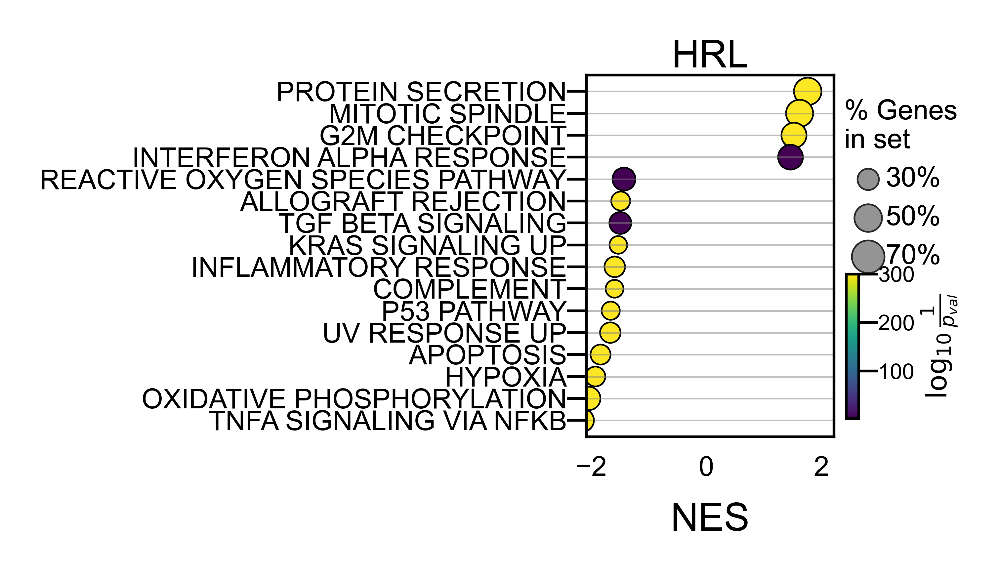

In [32]:
dfp2 = dfp.copy() # no term selection

# Parameters
dot_scale = .5   # smaller dot size multiplier
cmap = plt.cm.viridis

# Plot
fig, ax = plt.subplots(figsize=(.8
                                , 1.2))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * .97, nes_max * 1.03])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=5)
ax.tick_params(axis='y', labelsize=5)
ax.set_title(group_label, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$\log_{10}\frac{1}{p_{val}}$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.6, 1)
)
ax.add_artist(leg1)

# plt.tight_layout()
plt.savefig(f"plots/Figure6/{celltype_major}_{group_label}_GSEA_hallmark.svg", 
            bbox_inches='tight'
            )

### Immport

In [91]:
gene_corr_df = pd.read_csv(f'data/Figure6/{celltype_major}_{group_label}_gene_CorrWithRace.csv',
                          index_col=0)


pre_res = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                     gene_sets='data/11_genesets/immport_allgenelist.gmt',
                     threads=1,
                     min_size=5,
                     max_size=1000,
                     permutation_num=1000, # reduce number to speed up testing
                     outdir=None, # don't write to disk
                     seed=1024,
                     verbose=True, # see what's going on behind the scenes
                    )


2025-12-17 16:20:26,251 [WARNING] Duplicated values found in preranked stats: 21.40% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-12-17 16:20:26,253 [INFO] Parsing data files for GSEA.............................
2025-12-17 16:20:26,286 [INFO] 0035 gene_sets have been filtered out when max_size=1000 and min_size=5
2025-12-17 16:20:26,288 [INFO] 0118 gene_sets used for further statistical testing.....
2025-12-17 16:20:26,289 [INFO] Start to run GSEA...Might take a while..................
2025-12-17 16:20:38,440 [INFO] Congratulations. GSEApy runs successfully................



In [92]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Tag %'] = (
    dfp['Tag %']
    .astype(str)
    .apply(lambda x: eval(x) if '/' in x else float(x))
)
dfp['Tag %'] = dfp['Tag %'] * 100
dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))

# Sort by NES
dfp = dfp.sort_values('NES', ascending=False)

# filter - 
# dfp = dfp[dfp['Tag %']>=30]
dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]

dfp

/tmp/ipykernel_2102617/3250590676.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p
14,prerank,LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY ...,-0.582017,-1.659582,0.017316,0.041741,0.196,25.806452,5.86%,TYROBP;ITGB2;AIF1;TLR2;CX3CR1;ITGAM;CLU;SNCA,1.761552
13,prerank,INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE...,-0.49146,-1.66374,0.0,0.04233,0.189,26.229508,6.07%,FCN1;TYROBP;NFKBIA;LILRA2;CD14;TLR2;PAK1;TLR4;...,300.000000
12,prerank,NEGATIVE REGULATION OF HEMOPOIESIS,-0.45904,-1.681665,0.0,0.037857,0.157,18.446602,5.50%,FCGR2B;CEBPA;ID2;TMEM176B;ANXA1;TMEM176A;MAFB;...,300.000000
11,prerank,INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS,-0.569883,-1.688407,0.0,0.039079,0.152,37.142857,10.50%,FCER1A;FCGR2B;FCGR2A;IL1RN;HMGB2;FCGR1A;RAB44;...,300.000000
10,prerank,ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE,-0.651411,-1.711686,0.007905,0.03537,0.127,35.000000,7.38%,RNASE2;RPL39;FAU;NOD2;FFAR3;RNASE3;PLA2G1B,2.102091
9,prerank,LEUKOCYTE CHEMOTAXIS,-0.452702,-1.714015,0.0,0.037876,0.123,23.134328,7.75%,S100A9;S100A8;ITGB2;CSF3R;LGALS3;S100A12;NINJ1...,300.000000
8,prerank,IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHO...,-0.471711,-1.801609,0.0,0.014028,0.047,25.203252,5.46%,TYROBP;ITGB2;CD300C;FCGR2B;CD1D;LILRA2;PILRA;C...,300.000000
7,prerank,"COMPLEMENT ACTIVATION, LECTIN PATHWAY",-0.97483,-1.827712,0.0,0.011273,0.033,16.666667,0.01%,FCN1,300.000000
6,prerank,INTERLEUKIN-10 SIGNALING,-0.591611,-1.869088,0.0,0.00957,0.025,33.333333,8.40%,FPR1;TIMP1;IL1RN;TNFRSF1B;IL1B;CCL3;PTAFR;CCL5...,300.000000
5,prerank,LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY R...,-0.735904,-1.893479,0.003534,0.008589,0.019,27.777778,1.94%,S100A9;S100A8;NINJ1;ALOX5;ADAM8,2.451786


In [93]:
for term in dfp['Term']:
    print(term)

LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE
INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY
NEGATIVE REGULATION OF HEMOPOIESIS
INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS
ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE
LEUKOCYTE CHEMOTAXIS
IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL
COMPLEMENT ACTIVATION, LECTIN PATHWAY
INTERLEUKIN-10 SIGNALING
LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE
INNATE IMMUNE RESPONSE IN MUCOSA
ANTIMICROBIAL PEPTIDES
INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING
ANTIMICROBIAL HUMORAL RESPONSE
NEUTROPHIL DEGRANULATION


In [94]:
# terms_sel = [
# 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
# 'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
# 'INTERLEUKIN-10 SIGNALING',
# # 'INNATE IMMUNE RESPONSE IN MUCOSA',
# 'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING'
# ]

terms_sel = dfp['Term'].values

/tmp/ipykernel_2102617/2496719573.py:76: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  plt.draw()
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


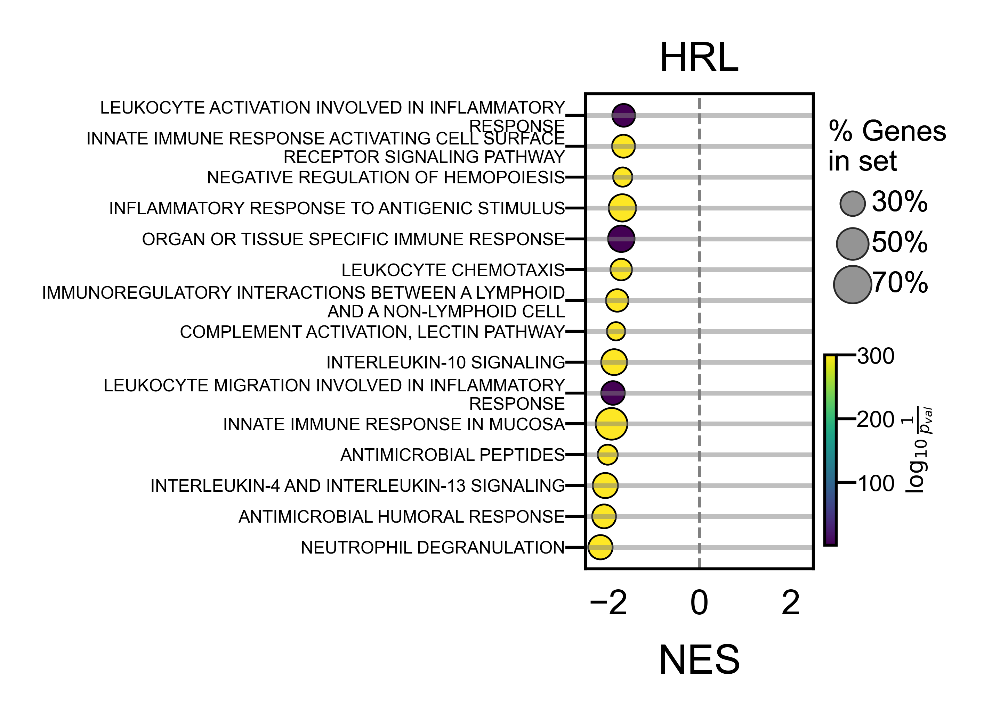

In [97]:
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from textwrap import fill

# Parameters
dot_scale = 0.6
cmap = cm.viridis
wrap_width = 50  # number of characters before wrapping a label

# Wrap long term names for y-axis
dfp_plot = dfp[dfp['Term'].isin(terms_sel)].copy() # no term selection
dfp_plot['Term_wrapped'] = dfp_plot['Term'].apply(lambda x: fill(x, width=wrap_width))

# Plot setup
fig, ax = plt.subplots(figsize=(.7, 1.5
                               ), constrained_layout=True)  # wider if needed for long labels
sc = ax.scatter(
    dfp_plot['NES'],
    dfp_plot['Term_wrapped'],
    s=dfp_plot['Tag %'] * dot_scale,
    c=dfp_plot['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()

# Axis labels
nes_max = dfp['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp['NES'].min()
ax.set_xlim([nes_min * 1.15, nes_max * 1.15])


ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=6)
ax.tick_params(axis='y', labelsize=3)
ax.set_title(group_label, fontsize=7, pad=4)

ax.axvline(x=0, linestyle='--', color='gray')
# Horizontal gridlines
ax.grid(axis='y', linestyle='-', color='gray', alpha=0.5)


# Colorbar inset
axins = inset_axes(ax,
                   width="5%",
                   height="40%",
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
cbar.set_label(r"$\log_{10}\frac{1}{p_{val}}$", fontsize=4, labelpad=1)
cbar.ax.tick_params(labelsize=4)

# Dot size legend
for size in [30, 50, 70]:
    ax.scatter([], [], s=size * dot_scale, c='gray', alpha=0.6,
               edgecolor='black', linewidth=0.3, label=f"{size}%")

leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5,
    fontsize=5, frameon=False,
    loc='upper right', bbox_to_anchor=(1.7, 1)
)
ax.add_artist(leg1)

# Layout & save
plt.draw() 
# plt.savefig(f"plots/Figure6/{celltype_major}_{group_label}_GSEA_immport.png", dpi=600, bbox_inches='tight')
plt.show()

## DCIS

In [40]:
celltype_major = 'DC'
group_name = 1
group_label = 'DCIS'


d_sub = dat[
    (dat.obs['predicted.celltype.l1']==celltype_major) &
    (dat.obs['group']==group_name)
    ]

In [41]:
import scanpy as sc

sc.pp.neighbors(d_sub)

# NO obesity pt
samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                               ['race','age','diabetes'],     # the metadata columns to use
                               'dataset_name')                        # the column of d.obs that contains sample IDs

samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]



res = cna.tl.association(
    d_sub,
    samplem.race, 
    'dataset_name',
    covs=samplem[['age','diabetes']],
    batches=samplem.batch,
    key_added='race_coef',
    return_full=True
)

/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 2 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

In [44]:
res = fast_spearman_ann(d_sub, obs_key='race_coef', genes=d_sub.var_names, chunk_size=2000)
res.sort_values('rho', ascending=False).head()

gene_corr_df = pd.DataFrame(res)
gene_corr_df.to_csv(f'data/Figure6/{celltype_major}_{group_label}_gene_CorrWithRace.csv')

### Hallmark

In [45]:
pre_res = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                     gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                     threads=1,
                     min_size=5,
                     max_size=1000,
                     permutation_num=1000, # reduce number to speed up testing
                     outdir=None, # don't write to disk
                     seed=1024,
                     verbose=True, # see what's going on behind the scenes
                    )

2025-12-17 16:06:13,168 [WARNING] Duplicated values found in preranked stats: 33.47% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-12-17 16:06:13,170 [INFO] Parsing data files for GSEA.............................
2025-12-17 16:06:13,205 [INFO] 0000 gene_sets have been filtered out when max_size=1000 and min_size=5
2025-12-17 16:06:13,207 [INFO] 0050 gene_sets used for further statistical testing.....
2025-12-17 16:06:13,208 [INFO] Start to run GSEA...Might take a while..................
2025-12-17 16:06:19,047 [INFO] Congratulations. GSEApy runs successfully................



In [46]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Tag %'] = (
    dfp['Tag %']
    .astype(str)
    .apply(lambda x: eval(x) if '/' in x else float(x))
)
dfp['Tag %'] = dfp['Tag %'] * 100
dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))

# Sort by NES
dfp = dfp.sort_values('NES', ascending=False)

# filter - 
# dfp = dfp[dfp['Tag %']>=30]
dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]
dfp

/tmp/ipykernel_2102617/2528169200.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p
6,prerank,MITOTIC SPINDLE,0.539658,1.604645,0.0,0.008291,0.014,42.211055,17.00%,CD2AP;FLNB;AKAP13;ARHGEF7;CCDC88A;RICTOR;TLK1;...,300.0
8,prerank,UV RESPONSE DN,0.532778,1.534782,0.0,0.020728,0.067,38.129496,16.57%,NRP1;TGFBR2;RUNX1;PIK3CD;CELF2;NR3C1;PTPRM;DYR...,300.0
9,prerank,G2M CHECKPOINT,0.516043,1.533772,0.0,0.014016,0.068,44.615385,21.22%,SLC7A5;STAG1;RBL1;STMN1;SLC12A2;MNAT1;PRIM2;SL...,300.0
13,prerank,MTORC1 SIGNALING,-0.389217,-1.396169,0.0,0.047515,0.136136,24.489796,7.51%,IFI30;GAPDH;CORO1A;CFP;ALDOA;TPI1;SERP1;ITGB2;...,300.0
11,prerank,UV RESPONSE UP,-0.41606,-1.427005,0.0,0.037456,0.099099,24.342105,7.50%,AP2S1;ALDOA;FOS;ARRB2;ATP6V1F;TST;SULT1A1;JUNB...,300.0
10,prerank,INTERFERON GAMMA RESPONSE,-0.421531,-1.506541,0.0,0.018059,0.043043,35.204082,9.59%,IFI30;CASP1;TNFAIP2;FGL2;HLA-A;IFITM2;IFITM3;H...,300.0
7,prerank,ADIPOGENESIS,-0.451839,-1.599966,0.0,0.006421,0.014014,29.591837,8.59%,ALDOA;ATP5PO;TKT;TALDO1;COX8A;UQCR11;UQCRQ;COX...,300.0
5,prerank,FATTY ACID METABOLISM,-0.479681,-1.640281,0.0,0.003746,0.007007,33.333333,9.40%,ALDOA;S100A10;LGALS1;PSME1;CD1D;MDH2;YWHAH;CBR...,300.0
4,prerank,ALLOGRAFT REJECTION,-0.4755,-1.696301,0.0,0.002568,0.004004,29.319372,7.75%,RPL39;IGSF6;CFP;TIMP1;CTSS;ITGB2;FGR;SPI1;RPS3...,300.0
3,prerank,INTERFERON ALPHA RESPONSE,-0.541945,-1.772001,0.0,0.000803,0.001001,47.916667,14.42%,IFI30;CASP1;HLA-C;IFITM2;IFITM3;PSME1;TXNIP;PS...,300.0


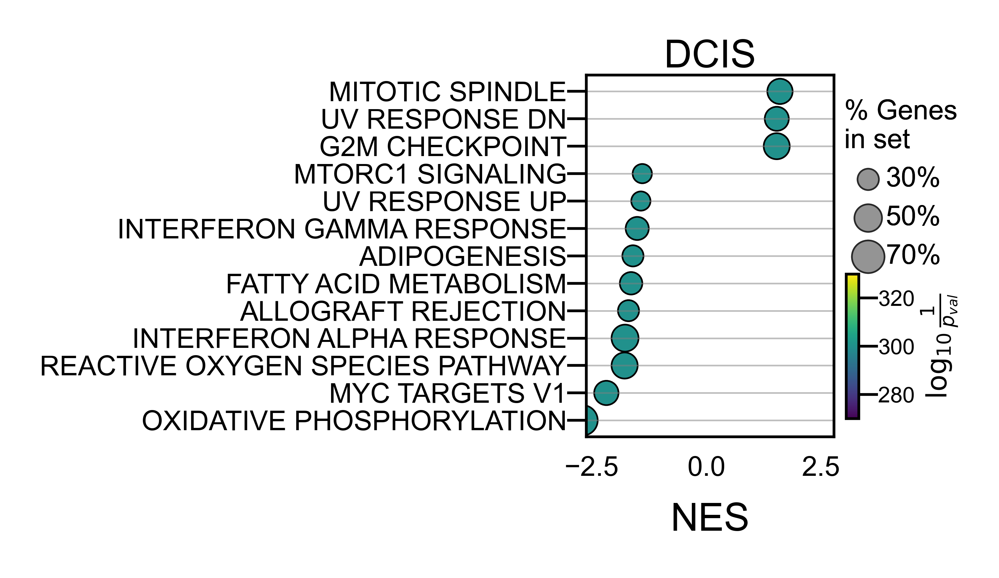

In [48]:
dfp2 = dfp.copy() # no term selection

# Parameters
dot_scale = .5   # smaller dot size multiplier
cmap = plt.cm.viridis

# Plot
fig, ax = plt.subplots(figsize=(.8
                                , 1.2))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * .97, nes_max * 1.03])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=5)
ax.tick_params(axis='y', labelsize=5)
ax.set_title(group_label, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$\log_{10}\frac{1}{p_{val}}$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.6, 1)
)
ax.add_artist(leg1)

# plt.tight_layout()
plt.savefig(f"plots/Figure6/{celltype_major}_{group_label}_GSEA_hallmark.svg", 
            bbox_inches='tight'
            )

### Immport

In [49]:
pre_res = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                     gene_sets='data/11_genesets/immport_allgenelist.gmt',
                     threads=1,
                     min_size=5,
                     max_size=1000,
                     permutation_num=1000, # reduce number to speed up testing
                     outdir=None, # don't write to disk
                     seed=1024,
                     verbose=True, # see what's going on behind the scenes
                    )


2025-12-17 16:07:25,867 [WARNING] Duplicated values found in preranked stats: 33.47% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-12-17 16:07:25,867 [INFO] Parsing data files for GSEA.............................
2025-12-17 16:07:25,904 [INFO] 0035 gene_sets have been filtered out when max_size=1000 and min_size=5
2025-12-17 16:07:25,906 [INFO] 0118 gene_sets used for further statistical testing.....
2025-12-17 16:07:25,907 [INFO] Start to run GSEA...Might take a while..................
2025-12-17 16:07:38,283 [INFO] Congratulations. GSEApy runs successfully................



In [50]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Tag %'] = (
    dfp['Tag %']
    .astype(str)
    .apply(lambda x: eval(x) if '/' in x else float(x))
)
dfp['Tag %'] = dfp['Tag %'] * 100
dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))

# Sort by NES
dfp = dfp.sort_values('NES', ascending=False)

# filter - 
# dfp = dfp[dfp['Tag %']>=30]
dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]
dfp

/tmp/ipykernel_2102617/2528169200.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p
17,prerank,LEUKOCYTE MEDIATED CYTOTOXICITY,-0.532964,-1.607095,0.004587,0.041607,0.243,34.426230,9.67%,CTSH;HLA-A;LYST;PTPN6;FCGR2B;IL18;B2M;STXBP2;P...,2.338456
16,prerank,LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY ...,-0.601607,-1.611915,0.009901,0.042195,0.235,25.806452,5.14%,TYROBP;AIF1;ITGB2;CX3CR1;TLR2;GRN;C5AR1;C1QA,2.004321
15,prerank,ANTIGEN PROCESSING AND PRESENTATION,-0.49695,-1.635124,0.0,0.03465,0.185,26.086957,2.39%,IFI30;FCER1G;CTSS;HLA-C;CTSH;HLA-A;HLA-B;PSME1...,300.000000
14,prerank,LEUKOCYTE CHEMOTAXIS,-0.479905,-1.635668,0.0,0.036798,0.184,26.119403,6.72%,S100A9;ANXA1;FCER1G;CORO1A;S100A8;ITGB2;RPS19;...,300.000000
13,prerank,C-TYPE LECTIN RECEPTORS (CLRS),-0.480519,-1.659319,0.0,0.028832,0.143,44.117647,11.49%,FCER1G;PYCARD;CLEC10A;RPS27A;PSME1;UBA52;IL1B;...,300.000000
12,prerank,ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE,-0.695882,-1.665708,0.00625,0.029366,0.135,30.000000,3.97%,RPL39;FAU;RNASE2;IL6R;RNASE3;NOD2,2.204120
11,prerank,TCR SIGNALING,-0.490761,-1.67224,0.0,0.029787,0.127,40.517241,8.57%,RPS27A;PSME1;UBA52;PAK1;PSMA7;PSMB1;PSMB9;PSMB...,300.000000
10,prerank,NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS,-0.516194,-1.730153,0.0,0.014147,0.058,30.172414,10.28%,ANXA1;SPI1;RPS19;LGALS3;FGL2;HLA-A;CX3CR1;ARRB...,300.000000
9,prerank,INTERLEUKIN-1 FAMILY SIGNALING,-0.501548,-1.745187,0.0,0.013374,0.049,39.726027,11.12%,CASP1;RPS27A;PSME1;S100A12;UBA52;IRAK3;IL1B;PT...,300.000000
8,prerank,"COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY",-0.843168,-1.755711,0.009146,0.012968,0.044,25.000000,3.07%,CFP;CFD;VSIG4,2.038753


In [51]:
for term in dfp['Term']:
    print(term)

LEUKOCYTE MEDIATED CYTOTOXICITY
LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE
ANTIGEN PROCESSING AND PRESENTATION
LEUKOCYTE CHEMOTAXIS
C-TYPE LECTIN RECEPTORS (CLRS)
ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE
TCR SIGNALING
NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS
INTERLEUKIN-1 FAMILY SIGNALING
COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY
INTERLEUKIN-10 SIGNALING
ANTIMICROBIAL HUMORAL RESPONSE
INNATE IMMUNE RESPONSE IN MUCOSA
LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE
IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL
ANTIMICROBIAL PEPTIDES
TNFR2 NON-CANONICAL NF-KB PATHWAY
NEUTROPHIL DEGRANULATION


In [52]:
# terms_sel = [
# 'ROS AND RNS PRODUCTION IN PHAGOCYTES',
# 'LEUKOCYTE MEDIATED CYTOTOXICITY',
# 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
# 'C-TYPE LECTIN RECEPTORS (CLRS)',
# # 'TCR SIGNALING',
# 'INTERLEUKIN-1 FAMILY SIGNALING',
# 'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
# 'INTERLEUKIN-10 SIGNALING',
# 'ANTIMICROBIAL PEPTIDES',
# # 'INNATE IMMUNE RESPONSE IN MUCOSA',
# 'TNFR2 NON-CANONICAL NF-KB PATHWAY',
# 'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE'#,
# # 'NEUTROPHIL DEGRANULATION'
# ]
terms_sel = dfp['Term'].values

/tmp/ipykernel_2102617/278051505.py:76: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  plt.draw()
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


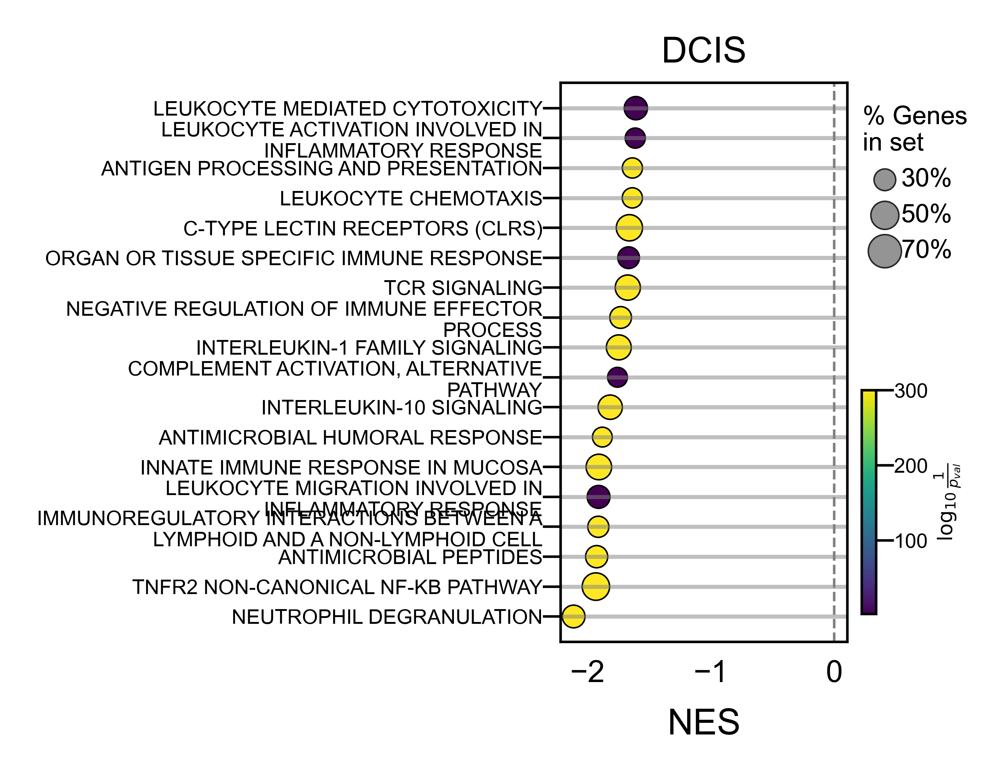

In [56]:
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from textwrap import fill

# Parameters
dot_scale = 0.6
cmap = cm.viridis
wrap_width = 40  # number of characters before wrapping a label

# Wrap long term names for y-axis
dfp_plot = dfp[dfp['Term'].isin(terms_sel)].copy() # no term selection
dfp_plot['Term_wrapped'] = dfp_plot['Term'].apply(lambda x: fill(x, width=wrap_width))

# Plot setup
fig, ax = plt.subplots(figsize=(1, 2
                               ), constrained_layout=True)  # wider if needed for long labels
sc = ax.scatter(
    dfp_plot['NES'],
    dfp_plot['Term_wrapped'],
    s=dfp_plot['Tag %'] * dot_scale,
    c=dfp_plot['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()

# Axis labels
# nes_max = dfp['NES'].abs().max()
# pad = nes_max * 0.01
# nes_min = dfp['NES'].min()
# ax.set_xlim([nes_min * 1.15, nes_max * 1.15])


ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=6)
ax.tick_params(axis='y', labelsize=4)
ax.set_title(group_label, fontsize=7, pad=4)

ax.axvline(x=0, linestyle='--', color='gray')
# Horizontal gridlines
ax.grid(axis='y', linestyle='-', color='gray', alpha=0.5)


# Colorbar inset
axins = inset_axes(ax,
                   width="5%",
                   height="40%",
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
cbar.set_label(r"$\log_{10}\frac{1}{p_{val}}$", fontsize=4, labelpad=1)
cbar.ax.tick_params(labelsize=4)

# Dot size legend
for size in [30, 50, 70]:
    ax.scatter([], [], s=size * dot_scale, c='gray', alpha=0.6,
               edgecolor='black', linewidth=0.3, label=f"{size}%")

leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5,
    fontsize=5, frameon=False,
    loc='upper right', bbox_to_anchor=(1.5, 1)
)
ax.add_artist(leg1)

# Layout & save
plt.draw() 
# plt.savefig(f"plots/Figure6/{celltype_major}_{group_label}_GSEA_immport.png", dpi=600, bbox_inches='tight')
plt.show()

## BC

In [57]:
celltype_major = 'DC'
group_name = 2
group_label = 'BC'


d_sub = dat[
    (dat.obs['predicted.celltype.l1']==celltype_major) &
    (dat.obs['group']==group_name)
    ]

In [58]:
import scanpy as sc

sc.pp.neighbors(d_sub)


samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                               ['race','age','obesity','diabetes'],     # the metadata columns to use
                               'dataset_name')                        # the column of d.obs that contains sample IDs

samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]



res = cna.tl.association(
    d_sub,
    samplem.race, 
    'dataset_name',
    covs=samplem[['age','obesity','diabetes']],
    batches=samplem.batch,
    key_added='race_coef',
    return_full=True
)

/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.obs. Overwriting.")


In [60]:
res = fast_spearman_ann(d_sub, obs_key='race_coef', genes=d_sub.var_names, chunk_size=2000)
res.sort_values('rho', ascending=False).head()

gene_corr_df = pd.DataFrame(res)
gene_corr_df.to_csv(f'data/Figure6/{celltype_major}_{group_label}_gene_CorrWithRace.csv')

### Hallmark

In [61]:
pre_res = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                     gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                     threads=1,
                     min_size=5,
                     max_size=1000,
                     permutation_num=1000, # reduce number to speed up testing
                     outdir=None, # don't write to disk
                     seed=1024,
                     verbose=True, # see what's going on behind the scenes
                    )

2025-12-17 16:09:37,099 [WARNING] Duplicated values found in preranked stats: 23.70% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-12-17 16:09:37,101 [INFO] Parsing data files for GSEA.............................
2025-12-17 16:09:37,136 [INFO] 0000 gene_sets have been filtered out when max_size=1000 and min_size=5
2025-12-17 16:09:37,138 [INFO] 0050 gene_sets used for further statistical testing.....
2025-12-17 16:09:37,138 [INFO] Start to run GSEA...Might take a while..................
2025-12-17 16:09:43,476 [INFO] Congratulations. GSEApy runs successfully................



In [63]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Tag %'] = (
    dfp['Tag %']
    .astype(str)
    .apply(lambda x: eval(x) if '/' in x else float(x))
)
dfp['Tag %'] = dfp['Tag %'] * 100
dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))

# Sort by NES
dfp = dfp.sort_values('NES', ascending=False)

# filter - 
# dfp = dfp[dfp['Tag %']>=30]
dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]
dfp

/tmp/ipykernel_2102617/2528169200.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p
0,prerank,INTERFERON ALPHA RESPONSE,0.405016,1.985276,0.0,0.0,0.0,25.000000,3.41%,IFI44L;IFITM3;IFITM1;CD74;LY6E;IFIT3;MX1;IFI44...,300.0
3,prerank,INTERFERON GAMMA RESPONSE,0.322628,1.506706,0.0,0.017493,0.004,22.448980,4.05%,IFI44L;IDO1;IFITM3;CDKN1A;CD74;LY6E;HLA-A;IFIT...,300.0
8,prerank,ADIPOGENESIS,-0.525998,-1.341689,0.0,0.044756,0.275,51.020408,23.20%,CD36;SDHC;QDPR;CD302;TALDO1;PRDX3;DHRS7;IDH3A;...,300.0
7,prerank,FATTY ACID METABOLISM,-0.543793,-1.389566,0.0,0.023031,0.137,48.299320,23.62%,CD36;ERP29;CA2;HSD17B4;SDHC;APEX1;OSTC;CD1D;PT...,300.0
6,prerank,UNFOLDED PROTEIN RESPONSE,-0.558983,-1.40202,0.0,0.023473,0.119,68.224299,28.52%,RPS14;XBP1;EEF2;EIF4A1;EIF4A2;SPCS1;SERP1;PREB...,300.0
5,prerank,PROTEIN SECRETION,-0.590062,-1.465946,0.0,0.009702,0.041,47.368421,20.05%,CTSC;COPB2;CLTA;CLTC;LMAN1;VPS4B;USO1;ARCN1;SE...,300.0
4,prerank,MYC TARGETS V1,-0.583977,-1.497284,0.0,0.00631,0.02,64.615385,27.81%,RPS6;RACK1;MRPS18B;RPL6;CCT7;EIF4A1;RAN;RPLP0;...,300.0
2,prerank,OXIDATIVE PHOSPHORYLATION,-0.591762,-1.51333,0.0,0.008518,0.018,70.000000,30.34%,NDUFC1;NDUFS2;MRPL34;SDHC;ATP5F1B;TIMM10;NDUFB...,300.0
1,prerank,DNA REPAIR,-0.604963,-1.53822,0.0,0.014197,0.015,59.060403,23.70%,POLR3C;ERCC1;NFX1;XPC;PNP;RBX1;GTF2H5;POLB;POL...,300.0


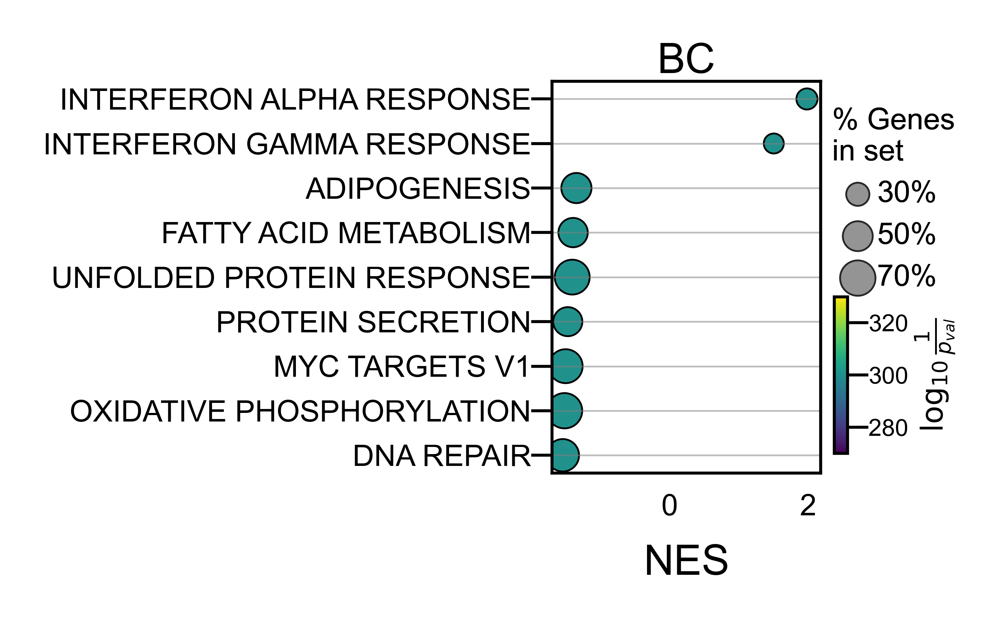

In [68]:
dfp2 = dfp.copy() # no term selection

# Parameters
dot_scale = .5   # smaller dot size multiplier
cmap = plt.cm.viridis

# Plot
fig, ax = plt.subplots(figsize=(.8
                                , 1.2))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.1, nes_max * 1.1])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=5)
ax.tick_params(axis='y', labelsize=5)
ax.set_title(group_label, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$\log_{10}\frac{1}{p_{val}}$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.6, 1)
)
ax.add_artist(leg1)

# plt.tight_layout()
# plt.savefig(f"plots/Figure6/{celltype_major}_{group_label}_GSEA_hallmark.svg", 
#             bbox_inches='tight'
#             )

### Immport

In [69]:
pre_res = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                     gene_sets='data/11_genesets/immport_allgenelist.gmt',
                     threads=1,
                     min_size=5,
                     max_size=1000,
                     permutation_num=1000, # reduce number to speed up testing
                     outdir=None, # don't write to disk
                     seed=1024,
                     verbose=True, # see what's going on behind the scenes
                    )


2025-12-17 16:14:32,276 [WARNING] Duplicated values found in preranked stats: 23.70% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-12-17 16:14:32,277 [INFO] Parsing data files for GSEA.............................
2025-12-17 16:14:32,314 [INFO] 0035 gene_sets have been filtered out when max_size=1000 and min_size=5
2025-12-17 16:14:32,316 [INFO] 0118 gene_sets used for further statistical testing.....
2025-12-17 16:14:32,317 [INFO] Start to run GSEA...Might take a while..................
2025-12-17 16:14:44,527 [INFO] Congratulations. GSEApy runs successfully................



In [70]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Tag %'] = (
    dfp['Tag %']
    .astype(str)
    .apply(lambda x: eval(x) if '/' in x else float(x))
)
dfp['Tag %'] = dfp['Tag %'] * 100
dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))

# Sort by NES
dfp = dfp.sort_values('NES', ascending=False)

# filter - 
# dfp = dfp[dfp['Tag %']>=30]
dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]
dfp

/tmp/ipykernel_2102617/2528169200.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p
6,prerank,ROS AND RNS PRODUCTION IN PHAGOCYTES,-0.664595,-1.52714,0.0,0.044723,0.162,54.285714,17.03%,ATP6V1B2;CYBB;HVCN1;NCF2;NCF4;ATP6V1A;ATP6V1G1...,300.000000
5,prerank,INTERLEUKIN-20 FAMILY SIGNALING,-0.706037,-1.539842,0.003222,0.046787,0.13,68.181818,25.63%,JAK1;IFNLR1;TYK2;STAT2;IL10RB;STAT3;STAT4;IFNL...,2.491828
4,prerank,CELLULAR EXTRAVASATION,-0.770638,-1.596122,0.001098,0.025687,0.047,43.750000,6.76%,CCR2;JAML;PIK3CD;PECAM1;SIRPA;PIK3CG;CD99,2.959518
3,prerank,"COMPLEMENT ACTIVATION, LECTIN PATHWAY",-0.934051,-1.619043,0.0,0.031192,0.033,16.666667,0.14%,FCN1,300.000000


In [71]:
for term in dfp['Term']:
    print(term)

ROS AND RNS PRODUCTION IN PHAGOCYTES
INTERLEUKIN-20 FAMILY SIGNALING
CELLULAR EXTRAVASATION
COMPLEMENT ACTIVATION, LECTIN PATHWAY


In [72]:
# terms_sel = [
# 'ROS AND RNS PRODUCTION IN PHAGOCYTES',
# 'CELLULAR EXTRAVASATION'#,
# # 'Complement activation, lectin pathway'
# ]
terms_sel = dfp['Term'].values


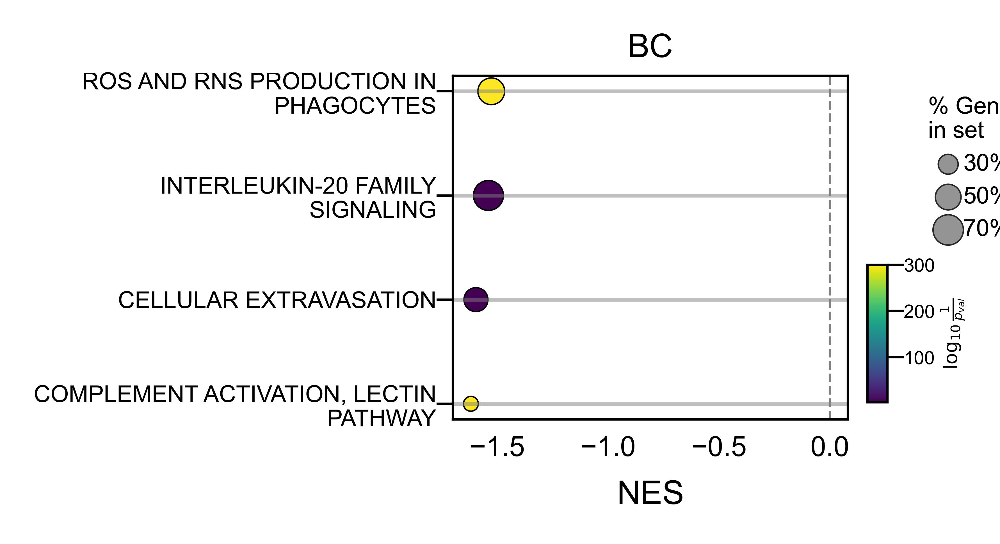

In [82]:
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from textwrap import fill

# Parameters
dot_scale = 0.6
cmap = cm.viridis
wrap_width = 30  # number of characters before wrapping a label

# Wrap long term names for y-axis
dfp_plot = dfp[dfp['Term'].isin(terms_sel)].copy() # no term selection
dfp_plot['Term_wrapped'] = dfp_plot['Term'].apply(lambda x: fill(x, width=wrap_width))

# Plot setup
fig, ax = plt.subplots(figsize=(2.5, 1.5
                               ), constrained_layout=True)  # wider if needed for long labels
sc = ax.scatter(
    dfp_plot['NES'],
    dfp_plot['Term_wrapped'],
    s=dfp_plot['Tag %'] * dot_scale,
    c=dfp_plot['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()

# Axis labels
# nes_max = dfp['NES'].max()
# pad = nes_max * 0.01
# nes_min = dfp['NES'].min()
# ax.set_xlim([nes_min * 1.15, nes_max * .95])

# ax.set_ylim([-.5,1.5])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=6)
ax.tick_params(axis='y', labelsize=5)
ax.set_title(group_label, fontsize=7, pad=4)

ax.axvline(x=0, linestyle='--', color='gray')
# Horizontal gridlines
ax.grid(axis='y', linestyle='-', color='gray', alpha=0.5)


# Colorbar inset
axins = inset_axes(ax,
                   width="5%",
                   height="40%",
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
cbar.set_label(r"$\log_{10}\frac{1}{p_{val}}$", fontsize=4, labelpad=1)
cbar.ax.tick_params(labelsize=4)

# Dot size legend
for size in [30, 50, 70]:
    ax.scatter([], [], s=size * dot_scale, c='gray', alpha=0.6,
               edgecolor='black', linewidth=0.3, label=f"{size}%")

leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5,
    fontsize=5, frameon=False,
    loc='upper right', bbox_to_anchor=(1.5, 1)
)
ax.add_artist(leg1)

# Layout & save
plt.draw() 
plt.savefig(f"plots/Figure6/{celltype_major}_{group_label}_GSEA_immport.png", dpi=600, bbox_inches='tight')
plt.show()

## HRL

In [123]:
d_sub = d[d.obs['group']==0]

res = fast_spearman_ann(d_sub, obs_key='race_coef', genes=d.var_names, chunk_size=2000)
res.sort_values('rho', ascending=False).head()

gene_corr_df = pd.DataFrame(res)
gene_corr_df.to_csv('data/Figure5/DC_HRL_gene_CorrWithRace.csv')

In [104]:
gene_corr_df = pd.read_csv('data/Figure5/DC_HRL_gene_CorrWithRace.csv', 
                          index_col=0)

pre_res = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                     gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                     threads=1,
                     min_size=5,
                     max_size=1000,
                     permutation_num=1000, # reduce number to speed up testing
                     outdir=None, # don't write to disk
                     seed=1024,
                     verbose=True, # see what's going on behind the scenes


2025-08-13 16:33:01,501 [WARNING] Duplicated values found in preranked stats: 21.40% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-08-13 16:33:01,504 [INFO] Parsing data files for GSEA.............................
2025-08-13 16:33:01,569 [INFO] 0000 gene_sets have been filtered out when max_size=1000 and min_size=5
2025-08-13 16:33:01,572 [INFO] 0050 gene_sets used for further statistical testing.....
2025-08-13 16:33:01,574 [INFO] Start to run GSEA...Might take a while..................
2025-08-13 16:33:12,029 [INFO] Congratulations. GSEApy runs successfully................



In [106]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Tag %'] = (
    dfp['Tag %']
    .astype(str)
    .apply(lambda x: eval(x) if '/' in x else float(x))
)
dfp['Tag %'] = dfp['Tag %'] * 100
dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))

# Sort by NES
dfp = dfp.sort_values('NES', ascending=False)

# filter - 
dfp = dfp[dfp['Tag %']>=30]
dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]
dfp

/tmp/ipykernel_2314087/346648306.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p
4,prerank,MITOTIC SPINDLE,0.527992,1.765446,0.0,0.001009,0.002,55.276382,24.66%,CD2AP;NET1;ARHGAP5;FLNB;CCDC88A;NEDD9;TLK1;RIC...,300.000000
5,prerank,PROTEIN SECRETION,0.55298,1.69792,0.0,0.001261,0.005,49.473684,18.89%,DOP1A;IGF2R;SCRN1;TPD52;DST;ARFGEF1;RPS6KA3;ST...,300.000000
7,prerank,INTERFERON ALPHA RESPONSE,0.527598,1.627861,0.001403,0.004539,0.026,41.666667,9.68%,MX1;IFI44L;NCOA7;TAP1;GMPR;LAP3;EIF2AK2;EPSTI1...,2.853090
9,prerank,INTERFERON GAMMA RESPONSE,0.484855,1.618774,0.0,0.003909,0.03,32.653061,9.10%,IDO1;AUTS2;SLAMF7;MX1;IFI44L;IRF8;P2RY14;PDE4B...,300.000000
15,prerank,UV RESPONSE DN,0.475041,1.524921,0.002642,0.012307,0.113,41.007194,17.15%,NRP1;KIT;TGFBR2;DLG1;TENT4A;NR3C1;SMAD3;PRDM2;...,2.578066
16,prerank,G2M CHECKPOINT,0.454836,1.52454,0.0,0.01034,0.114,41.025641,21.23%,CCND1;STAG1;TENT4A;KIF20B;SLC38A1;SMAD3;PRIM2;...,300.000000
19,prerank,ANDROGEN RESPONSE,0.474448,1.445366,0.009589,0.027237,0.306,30.208333,12.43%,CCND1;CDK6;PLPP1;B4GALT1;TPD52;NGLY1;RPS6KA3;D...,2.018225
21,prerank,NOTCH SIGNALING,0.564064,1.411892,0.058824,0.036568,0.428,40.000000,14.52%,CCND1;FBXW11;MAML2;FZD5;DTX4;NOTCH3;PSEN2;DTX2...,1.230449
22,prerank,WNT BETA CATENIN SIGNALING,0.526222,1.408665,0.054054,0.033625,0.434,30.000000,14.52%,NCOR2;CTNNB1;CSNK1E;ADAM17;PSEN2;NKD1;MAML1;HD...,1.267172
10,prerank,UV RESPONSE UP,-0.444631,-1.615109,0.0,0.012212,0.032,34.868421,12.83%,ALDOA;ARRB2;ATP6V1F;FOS;RHOB;NFKBIA;AP2S1;CA2;...,300.000000


In [40]:
for term in dfp['Term']:
    print(term)

COSTIMULATION BY THE CD28 FAMILY
INTERLEUKIN-12 FAMILY SIGNALING
NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR SIGNALING PATHWAY
INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY
MYELOID LEUKOCYTE ACTIVATION
LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE
ACTIVATION OF INNATE IMMUNE RESPONSE
MYELOID LEUKOCYTE MIGRATION
NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS
TCR SIGNALING
INTERLEUKIN-10 SIGNALING
INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY
SIGNALING BY THE B CELL RECEPTOR (BCR)
LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE
LEUKOCYTE CHEMOTAXIS
LEUKOCYTE MEDIATED CYTOTOXICITY
INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS
ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE
IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL
FC EPSILON RECEPTOR (FCERI) SIGNALING
ANTIMICROBIAL HUMORAL RESPONSE
INNATE IMMUNE RESPONSE IN MUCOSA
ROS AND RNS PRODUCTION IN PHAGOCYTES
ANTIMICROBIAL PEPTIDES
INT

In [ ]:
terms_sel = [
'COSTIMULATION BY THE CD28 FAMILY',
'INTERLEUKIN-12 FAMILY SIGNALING',
'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR SIGNALING PATHWAY',
'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
'MYELOID LEUKOCYTE ACTIVATION',
'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
'ACTIVATION OF INNATE IMMUNE RESPONSE',
'MYELOID LEUKOCYTE MIGRATION',
'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS',
'TCR SIGNALING',
'INTERLEUKIN-10 SIGNALING',
'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
'SIGNALING BY THE B CELL RECEPTOR (BCR)',
'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE',
'LEUKOCYTE CHEMOTAXIS',
'LEUKOCYTE MEDIATED CYTOTOXICITY',
'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
'FC EPSILON RECEPTOR (FCERI) SIGNALING',
'ANTIMICROBIAL HUMORAL RESPONSE',
'INNATE IMMUNE RESPONSE IN MUCOSA',
'ROS AND RNS PRODUCTION IN PHAGOCYTES',
'ANTIMICROBIAL PEPTIDES',
'INTERLEUKIN-1 FAMILY SIGNALING',
'C-TYPE LECTIN RECEPTORS (CLRS)',
'TNFR2 NON-CANONICAL NF-KB PATHWAY',
'NEUTROPHIL DEGRANULATION'   
]

## DCIS

In [113]:
d_sub = d[d.obs['group']==1]

res = fast_spearman_ann(d_sub, obs_key='race_coef', genes=d.var_names, chunk_size=2000)
res.sort_values('rho', ascending=False).head()

gene_corr_df = pd.DataFrame(res)
gene_corr_df.to_csv('data/Figure5/DC_DCIS_gene_CorrWithRace.csv')

In [114]:
gene_corr_df = pd.read_csv('data/Figure5/DC_DCIS_gene_CorrWithRace.csv', 
                          index_col=0)

pre_res = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                     gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                     threads=1,
                     min_size=5,
                     max_size=1000,
                     permutation_num=1000, # reduce number to speed up testing
                     outdir=None, # don't write to disk
                     seed=1024,
                     verbose=True, # see what's going on behind the scenes
                    )


2025-08-13 16:35:12,354 [WARNING] Duplicated values found in preranked stats: 33.46% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-08-13 16:35:12,355 [INFO] Parsing data files for GSEA.............................
2025-08-13 16:35:12,410 [INFO] 0000 gene_sets have been filtered out when max_size=1000 and min_size=5
2025-08-13 16:35:12,411 [INFO] 0050 gene_sets used for further statistical testing.....
2025-08-13 16:35:12,413 [INFO] Start to run GSEA...Might take a while..................
2025-08-13 16:35:22,158 [INFO] Congratulations. GSEApy runs successfully................



In [115]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Tag %'] = (
    dfp['Tag %']
    .astype(str)
    .apply(lambda x: eval(x) if '/' in x else float(x))
)
dfp['Tag %'] = dfp['Tag %'] * 100
dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))

# Sort by NES
dfp = dfp.sort_values('NES', ascending=False)

# filter - 
dfp = dfp[dfp['Tag %']>=30]
dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]
dfp

/tmp/ipykernel_2314087/346648306.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p
19,prerank,TNFA SIGNALING VIA NFKB,-0.439761,-1.439828,0.002786,0.021605,0.279,39.698492,17.34%,FOS;CEBPD;KLF2;IL1B;CEBPB;JUN;TLR2;TNFAIP2;NFK...,2.555094
18,prerank,INTERFERON GAMMA RESPONSE,-0.4406,-1.447409,0.005594,0.020184,0.252,34.183673,10.44%,IFI30;CASP1;HLA-A;TNFAIP2;TNFSF10;FPR1;LYSMD2;...,2.252246
15,prerank,APOPTOSIS,-0.477587,-1.513994,0.0,0.009879,0.124,30.322581,10.64%,TSPO;DPYD;CASP1;ANXA1;GPX4;TIMP1;IL1B;LGALS3;J...,300.000000
13,prerank,GLYCOLYSIS,-0.483276,-1.571549,0.0,0.005055,0.057,35.937500,16.56%,VCAN;ALDOA;TALDO1;GLRX;PGAM1;PYGL;PGK1;IL13RA1...,300.000000
12,prerank,DNA REPAIR,-0.493915,-1.574135,0.0,0.005263,0.055,47.651007,18.50%,GPX4;APRT;VPS28;VPS37B;GUK1;SUPT4H1;POLR2E;SDC...,300.000000
11,prerank,MTORC1 SIGNALING,-0.503801,-1.640615,0.0,0.001966,0.02,38.775510,15.93%,IFI30;SERP1;ALDOA;CORO1A;GAPDH;GLRX;ITGB2;CFP;...,300.000000
10,prerank,XENOBIOTIC METABOLISM,-0.503525,-1.643828,0.0,0.00193,0.018,35.911602,14.88%,CES1;BLVRB;GSTO1;COMT;NINJ1;CBR1;DCXR;FAS;ECH1...,300.000000
9,prerank,P53 PATHWAY,-0.498755,-1.644385,0.0,0.002123,0.018,34.375000,14.30%,S100A4;IFI30;CASP1;RACK1;FOS;RPL18;CEBPA;JUN;R...,300.000000
8,prerank,INTERFERON ALPHA RESPONSE,-0.553491,-1.662674,0.0,0.002097,0.016,31.250000,7.14%,IFI30;CASP1;UBE2L6;PSME1;B2M;PSMB8;HLA-C;PARP9...,300.000000
7,prerank,HYPOXIA,-0.523406,-1.687332,0.0,0.001474,0.01,30.687831,12.43%,S100A4;ALDOA;ANXA2;GAPDH;GLRX;FOS;JUN;PGK1;TPI...,300.000000


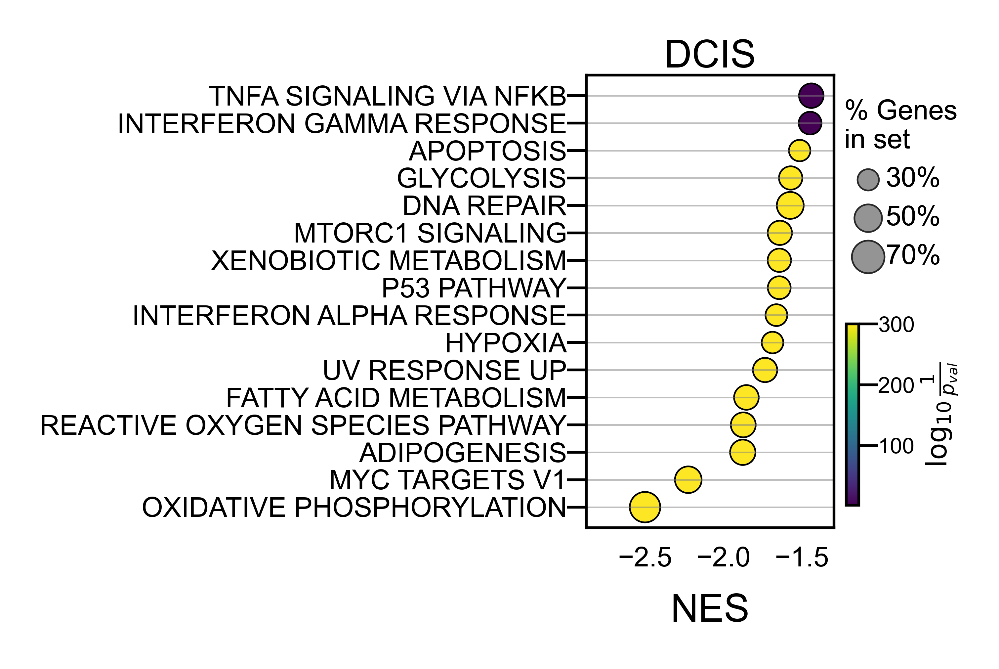

In [120]:
dfp2 = dfp.copy() # no term selection

# Parameters
dot_scale = .5   # smaller dot size multiplier
cmap = plt.cm.viridis

# Plot
fig, ax = plt.subplots(figsize=(.8
                                , 1.5))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()


# Axis labels & ticks
nes_max = dfp2['NES'].max() #.abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.15, nes_max * .9])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=5)
ax.tick_params(axis='y', labelsize=5)
ax.set_title("DCIS", fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$\log_{10}\frac{1}{p_{val}}$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.6, 1)
)
ax.add_artist(leg1)

# plt.tight_layout()
plt.savefig("plots/Figure5/DC_DCIS_GSEA_hallmark_custom.svg", 
            bbox_inches='tight'
            )

## BC

In [122]:
d_sub = d[d.obs['group']==2]

res = fast_spearman_ann(d_sub, obs_key='race_coef', genes=d.var_names, chunk_size=2000)
res.sort_values('rho', ascending=False).head()

gene_corr_df = pd.DataFrame(res)
gene_corr_df.to_csv('data/Figure5/DC_BC_gene_CorrWithRace.csv')

In [124]:
gene_corr_df = pd.read_csv('data/Figure5/DC_BC_gene_CorrWithRace.csv', 
                          index_col=0)

pre_res = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                     gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                     threads=1,
                     min_size=5,
                     max_size=1000,
                     permutation_num=1000, # reduce number to speed up testing
                     outdir=None, # don't write to disk
                     seed=1024,
                     verbose=True, # see what's going on behind the scenes
                    )


2025-08-13 16:37:22,801 [WARNING] Duplicated values found in preranked stats: 23.70% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-08-13 16:37:22,803 [INFO] Parsing data files for GSEA.............................
2025-08-13 16:37:22,857 [INFO] 0000 gene_sets have been filtered out when max_size=1000 and min_size=5
2025-08-13 16:37:22,859 [INFO] 0050 gene_sets used for further statistical testing.....
2025-08-13 16:37:22,860 [INFO] Start to run GSEA...Might take a while..................
2025-08-13 16:37:32,547 [INFO] Congratulations. GSEApy runs successfully................



In [125]:
pre_res_df = pre_res.res2d

# pre_res_df = pre_res_df[pre_res_df['FDR q-val']<0.1].sort_values('NES', ascending=False)
dfp = pre_res_df[pre_res_df['FDR q-val']<0.05].sort_values('NES', ascending=False)

dfp['Tag %'] = (
    dfp['Tag %']
    .astype(str)
    .apply(lambda x: eval(x) if '/' in x else float(x))
)
dfp['Tag %'] = dfp['Tag %'] * 100
dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))

# Sort by NES
dfp = dfp.sort_values('NES', ascending=False)

# filter - 
dfp = dfp[dfp['Tag %']>=30]
dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]
dfp

/tmp/ipykernel_2314087/346648306.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p
0,prerank,INTERFERON ALPHA RESPONSE,0.53706,2.10524,0.0,0.0,0.0,40.625000,4.62%,IFI44L;MX1;IFITM1;IFITM3;IFIT3;LY6E;ISG20;IRF7...,300.000000
3,prerank,INTERFERON GAMMA RESPONSE,0.436066,1.671024,0.0,0.00995,0.005,30.102041,4.62%,IFI44L;IDO1;MX1;IRF8;SLAMF7;IFITM3;IFIT3;LY6E;...,300.000000
8,prerank,MYC TARGETS V2,-0.550076,-1.390421,0.022293,0.042115,0.266,52.631579,23.58%,HK2;WDR74;PPAN;SLC19A1;FARSA;SRM;NOP2;AIMP2;HS...,1.651832
7,prerank,ADIPOGENESIS,-0.564986,-1.53668,0.0,0.003599,0.023,43.877551,15.43%,CD302;CD36;APLP2;ALDOA;TALDO1;ATP5PO;TKT;UQCR1...,300.000000
6,prerank,REACTIVE OXYGEN SPECIES PATHWAY,-0.647612,-1.596897,0.0,0.000751,0.004,48.979592,16.66%,FTL;MGST1;GLRX;IPCEF1;NDUFS2;LAMTOR5;PRDX1;GPX...,300.000000
5,prerank,FATTY ACID METABOLISM,-0.602289,-1.609414,0.0,0.000704,0.003,51.020408,20.73%,CD1D;CD36;ALDOA;CA2;LGALS1;APEX1;SDHC;MDH2;ACA...,300.000000
4,prerank,DNA REPAIR,-0.594967,-1.610865,0.0,0.000626,0.002,54.362416,20.66%,POLR2J;POLR2E;PNP;GTF2A2;GTF2H5;POLE4;SUPT4H1;...,300.000000
2,prerank,MYC TARGETS V1,-0.653839,-1.784693,0.0,0.0,0.0,60.512821,19.83%,RPS6;EIF4A1;RACK1;RPL6;RPS3;RPLP0;RPS2;SLC25A3...,300.000000
1,prerank,OXIDATIVE PHOSPHORYLATION,-0.720795,-1.963949,0.0,0.0,0.0,68.000000,17.16%,COX4I1;ATP5MG;ATP5PO;UQCRH;NDUFS2;ATP5MC2;UQCR...,300.000000


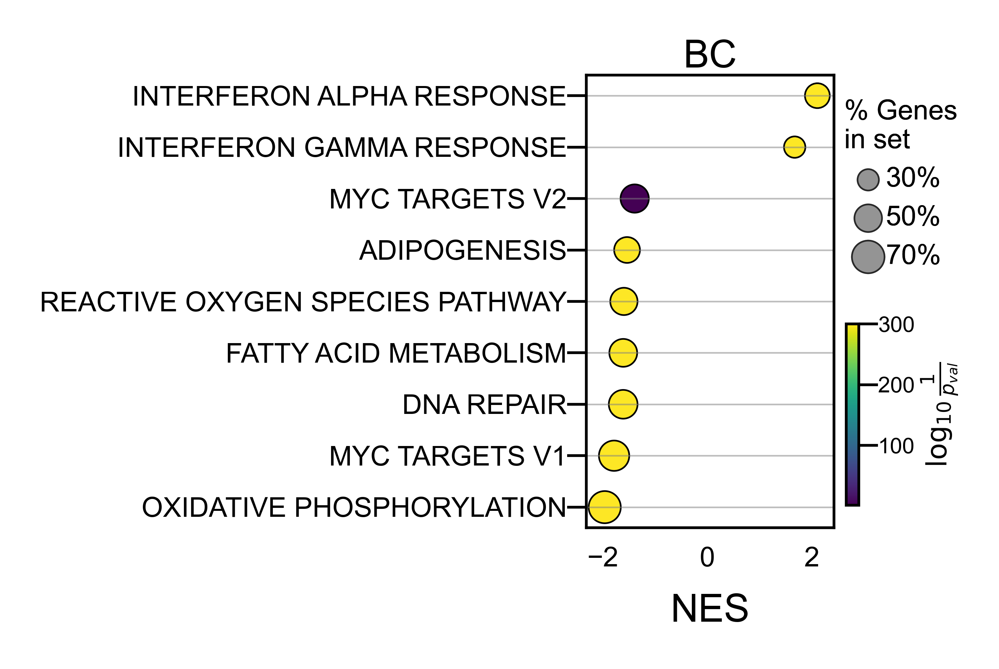

In [131]:
dfp2 = dfp.copy() # no term selection

# Parameters
dot_scale = .5   # smaller dot size multiplier
cmap = plt.cm.viridis

# Plot
fig, ax = plt.subplots(figsize=(.8
                                , 1.5))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.18, nes_max * 1.15])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=5)
ax.tick_params(axis='y', labelsize=5)
ax.set_title("BC", fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$\log_{10}\frac{1}{p_{val}}$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.6, 1)
)
ax.add_artist(leg1)

# plt.tight_layout()
plt.savefig("plots/Figure5/DC_BC_GSEA_hallmark_custom.svg", 
            bbox_inches='tight'
            )

# Corr heatmap

## HRL

In [132]:
rnk = pd.read_csv('data/Figure5/DC_HRL_gene_CorrWithRace.csv') # spearman corr


rnk = rnk[rnk['fdr']<0.05] # significant only
rnk  = rnk.sort_values('rho',ascending=False).dropna()
rnk

,gene,rho,pval,fdr
11900,CADM1,0.288473,3.447318e-69,2.402695e-65
12238,CLEC9A,0.283875,5.741737e-67,2.667898e-63
4847,CLNK,0.275279,6.321026e-63,2.202799e-59
8805,IDO1,0.262041,5.565477e-57,1.193538e-53
10363,WDFY4,0.260701,2.129505e-56,4.240605e-53
...,...,...,...,...
18484,TYROBP,-0.282164,3.757777e-66,1.496615e-62
18852,FTL,-0.284456,3.022163e-67,1.685097e-63
1296,S100A4,-0.297485,1.151106e-73,1.069723e-69
10024,FCN1,-0.298457,3.702821e-74,5.161547e-70


In [133]:
g_up = rnk['gene'][:15]
g_dn = rnk['gene'][-15:]

In [134]:
g_up = rnk['gene'][:15]
g_dn = rnk['gene'][-15:]

/tmp/ipykernel_2314087/4165694147.py:69: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


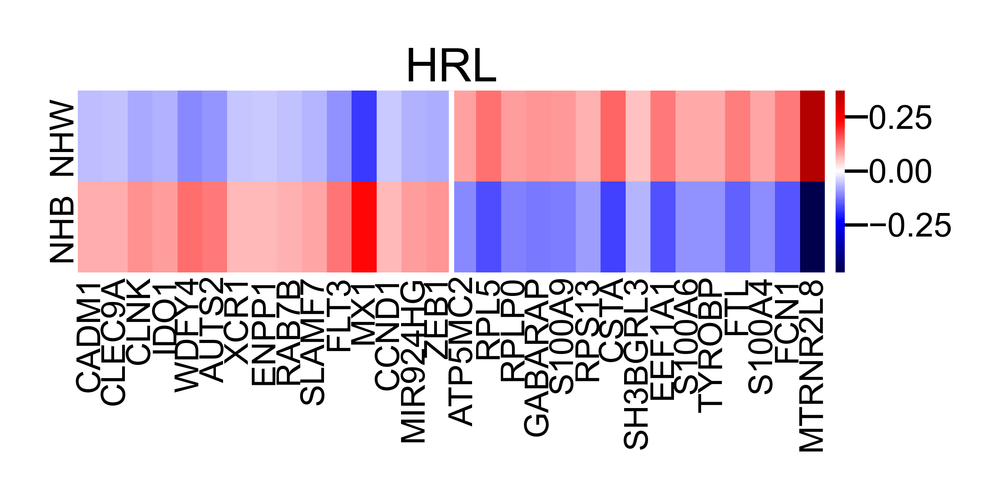

In [135]:
import numpy as np
import pandas as pd
from scipy import sparse
import seaborn as sns
import matplotlib.pyplot as plt

# --- inputs ---
order_rows = ['NHW-HRL', 'NHB-HRL']
genes_up = list(g_up)
genes_dn = list(g_dn)
genes_all = [g for g in (genes_up + genes_dn) if g in d.var_names]  # keep order

# --- slice expression for selected genes (cells x genes) ---
X = d_sub[:, genes_all].X
if sparse.issparse(X):
    X = X.toarray()

# --- z-score per gene across ALL patients ---
mu = X.mean(axis=0)
sigma = X.std(axis=0, ddof=0)
sigma_safe = np.where(sigma == 0, np.nan, sigma)
Z = (X - mu) / sigma_safe
Z = np.nan_to_num(Z, nan=0.0)

# --- average z-scores by race–stage group ---
zdf = pd.DataFrame(Z, index=d_sub.obs_names, columns=genes_all)
zdf['race-stage'] = d_sub.obs['race-stage'].astype(str).values
zmeans = (
    zdf.groupby('race-stage')[genes_all]
       .mean()
       .reindex(order_rows)  # enforce y-axis order
)

# --- flip orientation: y-axis = groups, x-axis = genes ---
mat = zmeans  # rows = groups, cols = genes

# optional: cap extreme z-scores for better visualization
mat_plot = mat.clip(lower=-3, upper=3)

# --- plot heatmap ---
plt.figure(figsize=(2.5, .5))  # adjust height for 6 groups
ax = sns.heatmap(
    mat_plot,
    cmap='seismic', center=0,
    cbar_kws={'label': ''},
    xticklabels=True, yticklabels=True
)

# Get the current position of the colorbar
cbar = ax.collections[0].colorbar
cbar_ax = cbar.ax
# Move the colorbar closer by editing its bounding box
pos = cbar_ax.get_position()
cbar_ax.set_position([pos.x0 - 0.03, pos.y0, pos.width, pos.height])  # shift left by 0.02

ax.set_title('HRL', fontsize=7, pad=-3)
ax.set_xlabel('', fontsize=8)
ax.set_ylabel('', fontsize=8)
ax.tick_params(axis='x', labelrotation=90, labelsize=5, pad=-3)
ax.tick_params(axis='y', labelrotation=90, length=0, labelsize=5)

ax.set_yticklabels([x.get_text().split('-')[0] for x in ax.get_yticklabels()])

# vertical separator between g_up and g_dn
sep = len([g for g in genes_up if g in genes_all])
if 0 < sep < len(genes_all):
    ax.vlines(sep, *ax.get_ylim(), colors='white', linewidth=0.8)

plt.tight_layout()
plt.savefig('plots/Figure5/DC_HRL_heatmap_meanZ_group_rows.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

## DCIS

In [136]:
rnk = pd.read_csv('data/Figure5/DC_DCIS_gene_CorrWithRace.csv') # spearman corr


rnk = rnk[rnk['fdr']<0.05] # significant only
rnk  = rnk.sort_values('rho',ascending=False).dropna()
rnk

,gene,rho,pval,fdr
12272,ETV6,0.304300,5.889778e-24,1.094674e-20
11900,CADM1,0.302923,9.589646e-24,1.670936e-20
12238,CLEC9A,0.288999,1.146780e-21,1.453231e-18
7912,AUTS2,0.287040,2.201900e-21,2.557782e-18
10363,WDFY4,0.285887,3.224194e-21,3.595492e-18
...,...,...,...,...
1294,S100A6,-0.347526,3.374657e-31,1.881641e-27
18852,FTL,-0.358078,3.786220e-33,2.638901e-29
18484,TYROBP,-0.359979,1.655851e-33,1.538783e-29
10024,FCN1,-0.367149,6.950083e-35,9.688068e-31


In [137]:
g_up = rnk['gene'][:15]
g_dn = rnk['gene'][-15:]

In [138]:
d_sub = d[d.obs['group']==1]

Counter(d_sub.obs['race-stage'])

Counter({'NHW-DCIS': 758, 'NHB-DCIS': 293})

/tmp/ipykernel_2314087/3198925158.py:69: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


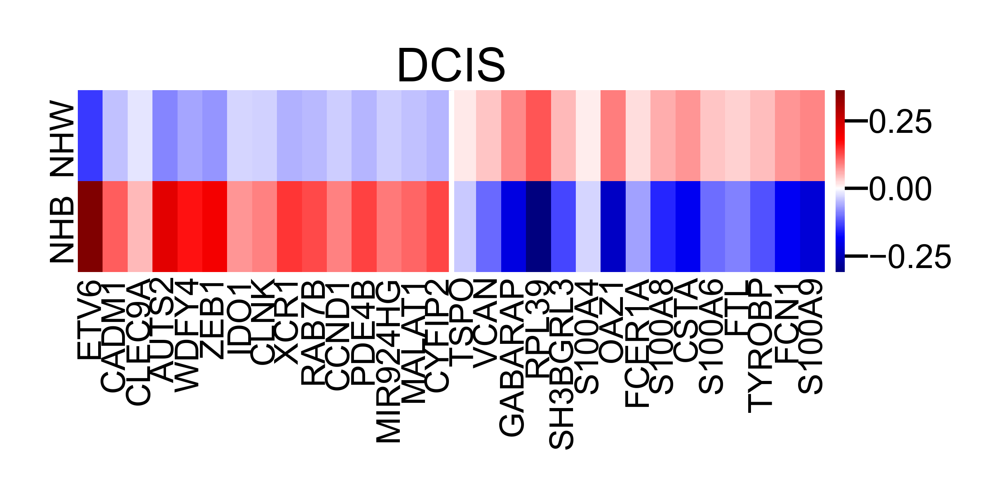

In [140]:
import numpy as np
import pandas as pd
from scipy import sparse
import seaborn as sns
import matplotlib.pyplot as plt

# --- inputs ---
order_rows = ['NHW-DCIS', 'NHB-DCIS']
genes_up = list(g_up)
genes_dn = list(g_dn)
genes_all = [g for g in (genes_up + genes_dn) if g in d.var_names]  # keep order

# --- slice expression for selected genes (cells x genes) ---
X = d_sub[:, genes_all].X
if sparse.issparse(X):
    X = X.toarray()

# --- z-score per gene across ALL patients ---
mu = X.mean(axis=0)
sigma = X.std(axis=0, ddof=0)
sigma_safe = np.where(sigma == 0, np.nan, sigma)
Z = (X - mu) / sigma_safe
Z = np.nan_to_num(Z, nan=0.0)

# --- average z-scores by race–stage group ---
zdf = pd.DataFrame(Z, index=d_sub.obs_names, columns=genes_all)
zdf['race-stage'] = d_sub.obs['race-stage'].astype(str).values
zmeans = (
    zdf.groupby('race-stage')[genes_all]
       .mean()
       .reindex(order_rows)  # enforce y-axis order
)

# --- flip orientation: y-axis = groups, x-axis = genes ---
mat = zmeans  # rows = groups, cols = genes

# optional: cap extreme z-scores for better visualization
mat_plot = mat.clip(lower=-3, upper=3)

# --- plot heatmap ---
plt.figure(figsize=(2.5, .5))  # adjust height for 6 groups
ax = sns.heatmap(
    mat_plot,
    cmap='seismic', center=0,
    cbar_kws={'label': ''},
    xticklabels=True, yticklabels=True
)

# Get the current position of the colorbar
cbar = ax.collections[0].colorbar
cbar_ax = cbar.ax
# Move the colorbar closer by editing its bounding box
pos = cbar_ax.get_position()
cbar_ax.set_position([pos.x0 - 0.03, pos.y0, pos.width, pos.height])  # shift left by 0.02

ax.set_title('DCIS', fontsize=7, pad=-3)
ax.set_xlabel('', fontsize=8)
ax.set_ylabel('', fontsize=8)
ax.tick_params(axis='x', labelrotation=90, labelsize=5, pad=-3)
ax.tick_params(axis='y', labelrotation=90, length=0, labelsize=5)

ax.set_yticklabels([x.get_text().split('-')[0] for x in ax.get_yticklabels()])

# vertical separator between g_up and g_dn
sep = len([g for g in genes_up if g in genes_all])
if 0 < sep < len(genes_all):
    ax.vlines(sep, *ax.get_ylim(), colors='white', linewidth=0.8)

plt.tight_layout()
plt.savefig('plots/Figure5/DC_DCIS_heatmap_meanZ_group_rows.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

## BC

In [141]:
rnk = pd.read_csv('data/Figure5/DC_BC_gene_CorrWithRace.csv') # spearman corr


rnk = rnk[rnk['fdr']<0.05] # significant only
rnk  = rnk.sort_values('rho',ascending=False).dropna()
rnk

,gene,rho,pval,fdr
843,IFI44L,0.239536,1.386519e-45,3.865476e-41
11900,CADM1,0.227138,4.800512e-41,2.230558e-37
6810,HLA-DQA2,0.212258,6.040342e-36,1.871096e-32
12238,CLEC9A,0.210365,2.529681e-35,7.052499e-32
3484,ARL4C,0.204690,1.704304e-33,4.319480e-30
...,...,...,...,...
4262,CSTA,-0.225006,2.722828e-40,1.084424e-36
9404,RPS6,-0.229018,1.023190e-41,5.705106e-38
1290,S100A9,-0.229649,6.074535e-42,4.233799e-38
6210,RPS14,-0.232677,4.855801e-43,4.512496e-39


In [142]:
g_up = rnk['gene'][:15]
g_dn = rnk['gene'][-15:]

In [143]:
d_sub = d[d.obs['group']==2]

Counter(d_sub.obs['race-stage'])

Counter({'NHW-BC': 1913, 'NHB-BC': 1488})

/tmp/ipykernel_2314087/3416652306.py:69: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


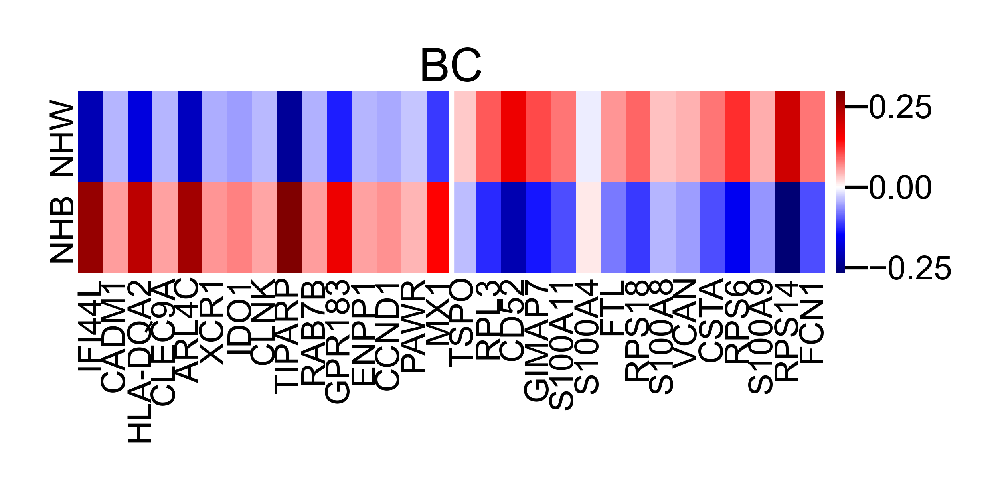

In [144]:
import numpy as np
import pandas as pd
from scipy import sparse
import seaborn as sns
import matplotlib.pyplot as plt

# --- inputs ---
order_rows = ['NHW-BC', 'NHB-BC']
genes_up = list(g_up)
genes_dn = list(g_dn)
genes_all = [g for g in (genes_up + genes_dn) if g in d.var_names]  # keep order

# --- slice expression for selected genes (cells x genes) ---
X = d_sub[:, genes_all].X
if sparse.issparse(X):
    X = X.toarray()

# --- z-score per gene across ALL patients ---
mu = X.mean(axis=0)
sigma = X.std(axis=0, ddof=0)
sigma_safe = np.where(sigma == 0, np.nan, sigma)
Z = (X - mu) / sigma_safe
Z = np.nan_to_num(Z, nan=0.0)

# --- average z-scores by race–stage group ---
zdf = pd.DataFrame(Z, index=d_sub.obs_names, columns=genes_all)
zdf['race-stage'] = d_sub.obs['race-stage'].astype(str).values
zmeans = (
    zdf.groupby('race-stage')[genes_all]
       .mean()
       .reindex(order_rows)  # enforce y-axis order
)

# --- flip orientation: y-axis = groups, x-axis = genes ---
mat = zmeans  # rows = groups, cols = genes

# optional: cap extreme z-scores for better visualization
mat_plot = mat.clip(lower=-3, upper=3)

# --- plot heatmap ---
plt.figure(figsize=(2.5, .5))  # adjust height for 6 groups
ax = sns.heatmap(
    mat_plot,
    cmap='seismic', center=0,
    cbar_kws={'label': ''},
    xticklabels=True, yticklabels=True
)

# Get the current position of the colorbar
cbar = ax.collections[0].colorbar
cbar_ax = cbar.ax
# Move the colorbar closer by editing its bounding box
pos = cbar_ax.get_position()
cbar_ax.set_position([pos.x0 - 0.03, pos.y0, pos.width, pos.height])  # shift left by 0.02

ax.set_title('BC', fontsize=7, pad=-3)
ax.set_xlabel('', fontsize=8)
ax.set_ylabel('', fontsize=8)
ax.tick_params(axis='x', labelrotation=90, labelsize=5, pad=-3)
ax.tick_params(axis='y', labelrotation=90, length=0, labelsize=5)

ax.set_yticklabels([x.get_text().split('-')[0] for x in ax.get_yticklabels()])

# vertical separator between g_up and g_dn
sep = len([g for g in genes_up if g in genes_all])
if 0 < sep < len(genes_all):
    ax.vlines(sep, *ax.get_ylim(), colors='white', linewidth=0.8)

plt.tight_layout()
plt.savefig('plots/Figure5/DC_BC_heatmap_meanZ_group_rows.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()